# 2. Neural-network study

**CSI 4106 Introduction to Artificial Intelligence**  
*Assignment 3: Designing and Diagnosing Neural Networks*  
*Due: November 16, 2026, at 11 PM*

# Identification
Report title: Designing and Diagnosing Neural Networks

# 1. Data and objective

The objective is to predict whether an autonomous underwater vehicle
returns before completing its planned survey. The positive class is
`mission_interrupted=1`.

The following cell supplies the imports, feature groups, fixed data
partitions, and an unfitted preprocessing factory used throughout the
assignment. Do not change the supplied feature groups, split settings,
or DataFrame and Series names. You remain responsible for fitting and
applying the preprocessor at the correct stages and for preparing the
NumPy arrays used by Keras.

## DISCLAIMER: Reproducibility and Training Variability

Although a fixed random seed (`4106`) is used, TensorFlow/Keras training may produce slightly different results across executions due to nondeterministic operations and runtime conditions. Consequently, checkpoint epochs, validation metrics, and model rankings may vary.

The final model was selected and locked during an earlier controlled run, achieving validation loss `0.3810` and F1 `0.7556` at epoch `82`. A subsequent execution identified epoch `134`, with a similar validation loss of `0.3804` and F1 `0.7540`. These differences illustrate how comparable performance can occur at different epochs.

**The original model configuration and locked epoch count are preserved to avoid modifying the selection after test evaluation.** Some written conclusions therefore reflect the original run rather than the latest outputs. While averaging results across multiple runs would provide stronger evidence of reproducibility, each complete notebook execution takes approximately 20 minutes. Repeating every experiment enough times to obtain reliable averages would require substantial computational time and effort, making this approach impractical for this assignment's scope.

In [4]:
from pathlib import Path
import math
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from tensorflow import keras


COMPLETE_URL = (
    "https://raw.githubusercontent.com/turcotte/csi4106-f26/main/"
    "assignments-data/a2/asrc_missions_complete.csv"
)
HIDDEN_URL = (
    "https://raw.githubusercontent.com/turcotte/csi4106-f26/main/"
    "assignments-data/a2/asrc_missions_hidden.csv"
)

COMPLETE_LOCAL_PATH = Path("asrc_missions_complete.csv")
HIDDEN_LOCAL_PATH = Path("asrc_missions_hidden.csv")

TARGET = "mission_interrupted"
NUMERIC_FEATURES = [
    "planned_depth_m",
    "descent_current_speed_m_s",
    "water_temperature_c",
    "sonar_noise_db",
    "navigation_drift_m",
    "battery_health_pct",
    "thruster_vibration_mm_s",
    "missions_since_service",
]
NOMINAL_FEATURES = ["vehicle_class", "seabed_terrain"]
ORDINAL_FEATURES = ["maintenance_grade"]
BINARY_FEATURES = ["firmware_current"]
FEATURES = (
    NUMERIC_FEATURES
    + NOMINAL_FEATURES
    + ORDINAL_FEATURES
    + BINARY_FEATURES
)
EXPECTED_COLUMNS = FEATURES + [TARGET]


def make_preprocessor():
    """Return a new, unfitted copy of the required preprocessor."""
    return ColumnTransformer(
        transformers=[
            ("numeric", StandardScaler(), NUMERIC_FEATURES),
            (
                "nominal",
                OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                NOMINAL_FEATURES,
            ),
            (
                "ordinal",
                OrdinalEncoder(
                    categories=[["poor", "fair", "good", "excellent"]]
                ),
                ORDINAL_FEATURES,
            ),
            ("binary", "passthrough", BINARY_FEATURES),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )


complete_source = COMPLETE_LOCAL_PATH if COMPLETE_LOCAL_PATH.exists() else COMPLETE_URL
missions = pd.read_csv(complete_source)

if list(missions.columns) != EXPECTED_COLUMNS:
    raise ValueError(
        "The complete data do not have the expected columns in the expected order."
    )
if len(missions) != 6371:
    raise ValueError(f"Expected 6,371 labelled missions, got {len(missions):,}.")
if missions.isna().any().any():
    raise ValueError("The complete data contain missing values.")
if not set(missions[TARGET].unique()).issubset({0, 1}):
    raise ValueError("The response must contain only 0 and 1.")

X_labelled = missions[FEATURES].copy()
y_labelled = missions[TARGET].copy()

X_development, X_test, y_development, y_test = train_test_split(
    X_labelled,
    y_labelled,
    test_size=0.20,
    random_state=4106,
    stratify=y_labelled,
)

X_neural_train, X_validation, y_neural_train, y_validation = train_test_split(
    X_development,
    y_development,
    test_size=0.20,
    random_state=4106,
    stratify=y_development,
)

print(f"Loaded labelled data from: {complete_source}")
print(f"Labelled data: {missions.shape}")
print(
    "Partitions: "
    f"neural training={len(X_neural_train)}, "
    f"validation={len(X_validation)}, "
    f"development={len(X_development)}, "
    f"test={len(X_test)}"
)

Loaded labelled data from: https://raw.githubusercontent.com/turcotte/csi4106-f26/main/assignments-data/a2/asrc_missions_complete.csv
Labelled data: (6371, 13)
Partitions: neural training=4076, validation=1020, development=5096, test=1275


## 2.1 Prepare and validate the neural-network inputs

Summarize the complete, development, neural-training, and validation
data as specified in Task 1. Report only the number of reserved test
observations before the final evaluation. Instantiate the supplied
preprocessor, fit it only on the neural-network training predictors, and
transform the validation predictors. Convert predictors and targets to
NumPy arrays suitable for Keras.

Validate and report the array shapes and data types. Confirm that all
values are finite, targets contain only `0` and `1`, and each predictor
array is aligned with its target array. Report the transformed input
width and explain the preprocessing and leakage boundary.

In [5]:
# 1. Summarize datasets and report reserved test count
print("=== Dataset Summaries ===")
print(f"First 5 Rows: {missions.head(5)}")
print(f"Complete dataset shape: {missions.shape}")
print(f"Reserved test observations (not evaluated yet): {len(X_test)}")

print("\n=== Development Summaries ===")
print(f"Development dataset shape: {X_development.shape}")
print(f"Development response count: {y_development.value_counts()}")
print(f"Development response proportions: {y_development.value_counts(normalize=True)}")

print("\n=== Neural-training Summaries ===")
print(f"Neural-training dataset shape: {X_neural_train.shape}")
print(f"Neural-training response count: {y_neural_train.value_counts()}")
print(f"Neural-training response proportions: {y_neural_train.value_counts(normalize=True)}")

print("\n=== Validation Summaries ===")
print(f"Validation dataset shape: {X_validation.shape}")
print(f"Validation response count: {y_validation.value_counts()}")
print(f"Validation response proportions: {y_validation.value_counts(normalize=True)}")

# 2. Instantiate and fit preprocessor on neural-training partition
preprocessor = make_preprocessor()

# Fit on training and transform training + validation
X_train_tf = preprocessor.fit_transform(X_neural_train)
X_val_tf = preprocessor.transform(X_validation)

# Convert to float32 NumPy arrays for Keras
X_train_arr = np.array(X_train_tf, dtype=np.float32)
X_val_arr = np.array(X_val_tf, dtype=np.float32)
y_train_arr = np.array(y_neural_train, dtype=np.int32)
y_val_arr = np.array(y_validation, dtype=np.int32)

# 3. Validation assertions
assert np.isfinite(X_train_arr).all(), "Training predictors contain non-finite values"
assert np.isfinite(X_val_arr).all(), "Validation predictors contain non-finite values"
assert set(np.unique(y_train_arr)).issubset({0, 1}), "Training targets contain invalid values"
assert set(np.unique(y_val_arr)).issubset({0, 1}), "Validation targets contain invalid values"
assert len(X_train_arr) == len(y_train_arr), "Training alignment mismatch"
assert len(X_val_arr) == len(y_val_arr), "Validation alignment mismatch"

# Report details
print("\n=== Array Verification ===")
print(f"Transformed Training Predictors: shape={X_train_arr.shape}, dtype={X_train_arr.dtype}")
print(f"Transformed Validation Predictors: shape={X_val_arr.shape}, dtype={X_val_arr.dtype}")
print(f"Training Targets: shape={y_train_arr.shape}, dtype={y_train_arr.dtype}")
print(f"Validation Targets: shape={y_val_arr.shape}, dtype={y_val_arr.dtype}")
print(f"Transformed input width (number of features): {X_train_arr.shape[1]}")

=== Dataset Summaries ===
First 5 Rows:    planned_depth_m  descent_current_speed_m_s  water_temperature_c  \
0           1400.0                       0.55                  3.3   
1           2700.0                       0.68                  3.0   
2           2870.0                       0.15                  3.6   
3           2840.0                       0.39                  2.5   
4           2430.0                       0.34                  2.8   

   sonar_noise_db  navigation_drift_m  battery_health_pct  \
0            66.0                10.4                87.0   
1            78.5                49.9                83.0   
2            78.7                 5.8                92.0   
3            77.3                54.6                89.0   
4            77.8                 8.7                89.0   

   thruster_vibration_mm_s  missions_since_service vehicle_class  \
0                      3.1                      14       compact   
1                      3.9          

### 2.1 Summary of Inputs & Preprocessing

#### Dataset Partition Dimensions
- **Complete**: 6,371 rows with 12 features and 1 binary target.
- **Development**: 5,096 rows representing an 80% stratified split of the complete data.
- **Neural-Training**: 4,076 rows representing an 80% stratified split of the development data.
- **Validation**: 1,020 rows representing a 20% stratified split of the development data.
- **Reserved Test Set**: 1,275 observations (20% of complete data) strictly held back.
- **Output Verification**: Inputs are transformed into numeric matrices of width **17** with final shapes of `(4076, 17)` for training and `(1020, 17)` for validation, stored as standard `float32` and `int32` NumPy arrays.

#### Feature Mapping to Preprocessing Techniques
- **Standardization (`StandardScaler`)**: Applied to all continuous numeric features (`planned_depth_m`, `descent_current_speed_m_s`, `water_temperature_c`, `sonar_noise_db`, `navigation_drift_m`, `battery_health_pct`, `thruster_vibration_mm_s`, `missions_since_service`) to normalize scale discrepancies.
- **One-Hot Encoding (`OneHotEncoder`)**: Applied to non-ordered categorical features (`vehicle_class`, `seabed_terrain`) to yield binary dummy vectors.
- **Ordinal Encoding (`OrdinalEncoder`)**: Applied to `maintenance_grade` (`poor`, `fair`, `good`, `excellent`) to preserve natural scale rankings as numeric levels.
- **Passthrough**: Applied to `firmware_current` because it is already a binary indicator requiring no transformation.

#### Data Leakage Boundary Reasoning
When preparing data for our models, fitting a preprocessor calculates parameters like the average and variance for numeric scaling, or categorical values for encoding. If we mistakenly fit this preprocessor on both the training and validation data together, we let statistical properties from the validation set leak into the training workflow. Because of this, the model gets exposed to validation distribution details ahead of time, which inflates the validation metrics artificially and hides whether the model can actually generalize to new data. Therefore, we must fit the preprocessor only on the training set, and then transform the validation set using those fitted parameters to keep our evaluation clean and realistic.

## 2.2 Connect logistic regression to a small neural network

Train the required no-hidden-layer and 8-unit models. Calculate and
verify their parameter counts, plot loss and positive-class F1 at
threshold `0.5`, report metrics recomputed after restoring the
lowest-validation-loss weights, diagnose their behaviour, and explain
the connection to logistic regression.

In [6]:
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers

In [7]:
# Model Checkpoint Directory
# Create a temporary directory to save each model's best weights during training, based on the lowest validation loss.
# These checkpoints are later restored for accurate evaluation. The directory is created automatically, so no external checkpoint files are required before execution.

CHECKPOINT_DIR = Path("checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

# Custom Callback to log threshold-0.5 Positive Class F1-Score for each epoch
class F1ScoreCallback(tf.keras.callbacks.Callback):
    def __init__(self, train_data, val_data):
        super().__init__()
        self.X_train, self.y_train = train_data
        self.X_val, self.y_val = val_data

    def on_train_begin(self, logs=None):
        self.model.history.history['train_f1'] = []
        self.model.history.history['val_f1'] = []

    def on_epoch_end(self, epoch, logs=None):
        # Training F1
        train_preds = (self.model.predict(self.X_train, verbose=0) > 0.5).astype(int)
        train_f1 = f1_score(self.y_train, train_preds, zero_division=0)
        self.model.history.history['train_f1'].append(train_f1)

        # Validation F1
        val_preds = (self.model.predict(self.X_val, verbose=0) > 0.5).astype(int)
        val_f1 = f1_score(self.y_val, val_preds, zero_division=0)
        self.model.history.history['val_f1'].append(val_f1)

In [8]:
# These two lines will be frequent accross the notebook,
# They clear previous model state and set a fixed seed for reproducibility.

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(4106)

In [9]:
# Input dimensionality is 17 features
input_shape = (X_train_arr.shape[1],)

# --- 1. Model with No Hidden Layer (Logistic Regression Equivalent) ---
model_no_hidden = models.Sequential([
    layers.Input(shape=input_shape),
    layers.Dense(1, activation='sigmoid')
])

model_no_hidden.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("=== Model 1: No Hidden Layer Summary ===")
model_no_hidden.summary()

=== Model 1: No Hidden Layer Summary ===


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │            18 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18 (72.00 B)

 Trainable params: 18 (72.00 B)

 Non-trainable params: 0 (0.00 B)

In [10]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(4106)

In [11]:
# --- 2. Model with One Hidden Layer (8 ReLU Units) ---
model_8_units = models.Sequential([
    layers.Input(shape=input_shape),
    layers.Dense(8, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model_8_units.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("\n=== Model 2: 8 Hidden Units Summary ===")
model_8_units.summary()


=== Model 2: 8 Hidden Units Summary ===


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 153 (612.00 B)

 Trainable params: 153 (612.00 B)

 Non-trainable params: 0 (0.00 B)

In [12]:
# --- Training both models for 100 epochs with Custom Callback ---
checkpoint_no_hidden = CHECKPOINT_DIR / "task22_no_hidden.weights.h5"
checkpoint_8_units = CHECKPOINT_DIR / "task22_8_units.weights.h5"
checkpoint_callback_no_hidden = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(checkpoint_no_hidden), monitor="val_loss", mode="min",
    save_best_only=True, save_weights_only=True
)
checkpoint_callback_8_units = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(checkpoint_8_units), monitor="val_loss", mode="min",
    save_best_only=True, save_weights_only=True
)

print("\nTraining Model 1 (No Hidden Layer)...")
history_no_hidden = model_no_hidden.fit(
    X_train_arr, y_train_arr,
    validation_data=(X_val_arr, y_val_arr),
    epochs=100,
    batch_size=64,
    callbacks=[F1ScoreCallback((X_train_arr, y_train_arr), (X_val_arr, y_val_arr)), checkpoint_callback_no_hidden],
    verbose=0
)

print("Training Model 2 (8 Hidden Units)...")
history_8_units = model_8_units.fit(
    X_train_arr, y_train_arr,
    validation_data=(X_val_arr, y_val_arr),
    epochs=100,
    batch_size=64,
    callbacks=[F1ScoreCallback((X_train_arr, y_train_arr), (X_val_arr, y_val_arr)), checkpoint_callback_8_units],
    verbose=0
)

print("\nTraining complete and variables saved!")


Training Model 1 (No Hidden Layer)...
Training Model 2 (8 Hidden Units)...

Training complete and variables saved!


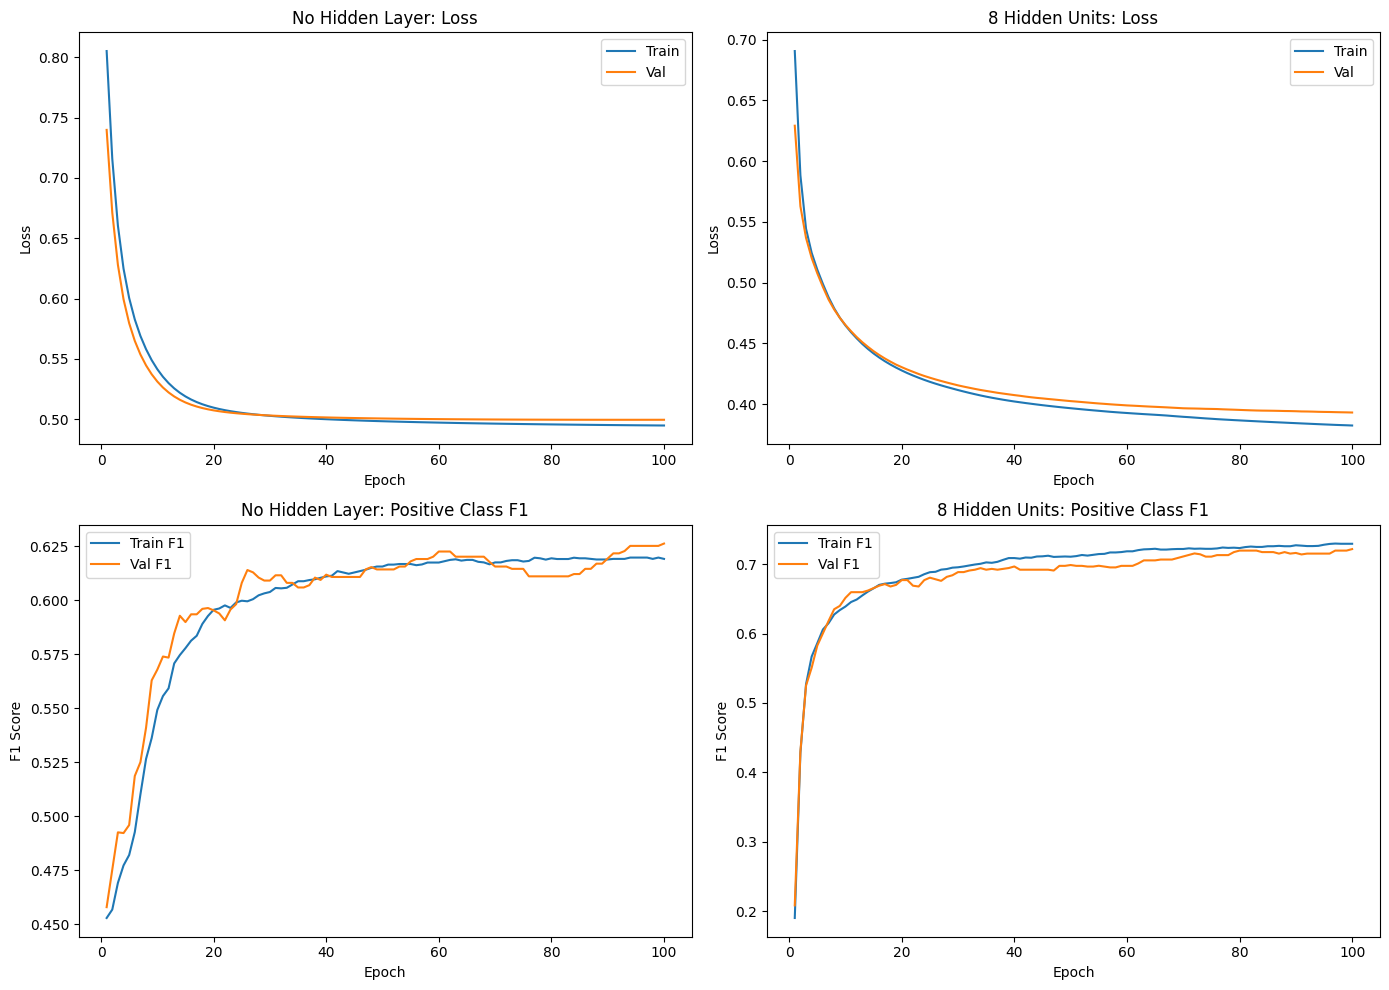

In [13]:
# Calculate and plot loss and F1-scores over epochs
epochs = range(1, 101)

fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# No Hidden - Loss
axs[0, 0].plot(epochs, history_no_hidden.history['loss'], label='Train')
axs[0, 0].plot(epochs, history_no_hidden.history['val_loss'], label='Val')
axs[0, 0].set_title('No Hidden Layer: Loss')
axs[0, 0].set_xlabel('Epoch')
axs[0, 0].set_ylabel('Loss')
axs[0, 0].legend()

# 8 Units - Loss
axs[0, 1].plot(epochs, history_8_units.history['loss'], label='Train')
axs[0, 1].plot(epochs, history_8_units.history['val_loss'], label='Val')
axs[0, 1].set_title('8 Hidden Units: Loss')
axs[0, 1].set_xlabel('Epoch')
axs[0, 1].set_ylabel('Loss')
axs[0, 1].legend()

# No Hidden - F1 Score
axs[1, 0].plot(epochs, history_no_hidden.history['train_f1'], label='Train F1')
axs[1, 0].plot(epochs, history_no_hidden.history['val_f1'], label='Val F1')
axs[1, 0].set_title('No Hidden Layer: Positive Class F1')
axs[1, 0].set_xlabel('Epoch')
axs[1, 0].set_ylabel('F1 Score')
axs[1, 0].legend()

# 8 Units - F1 Score
axs[1, 1].plot(epochs, history_8_units.history['train_f1'], label='Train F1')
axs[1, 1].plot(epochs, history_8_units.history['val_f1'], label='Val F1')
axs[1, 1].set_title('8 Hidden Units: Positive Class F1')
axs[1, 1].set_xlabel('Epoch')
axs[1, 1].set_ylabel('F1 Score')
axs[1, 1].legend()

plt.tight_layout()
plt.show()

In [14]:
# Calculate and verify parameters
print("=== Parameter Counting Verification ===")
no_hidden_params = model_no_hidden.count_params()
print(f"Model 1 (No Hidden Layer) parameters: 18. Actual: {no_hidden_params}")

model_8_params = model_8_units.count_params()
print(f"Model 2 (8 Hidden Units) parameters: 153. Actual: {model_8_params}")

# Find the best epoch based on lowest validation loss (0-indexed)
best_epoch_no_hidden = np.argmin(history_no_hidden.history['val_loss'])
best_epoch_8_units = np.argmin(history_8_units.history['val_loss'])

# Restore the minimum-validation-loss checkpoints before validation predictions
model_no_hidden.load_weights(checkpoint_no_hidden)
model_8_units.load_weights(checkpoint_8_units)

# Model 1 evaluation
val_probs_no_hidden = model_no_hidden.predict(X_val_arr, verbose=0)
val_preds_no_hidden = (val_probs_no_hidden > 0.5).astype(int)

# Model 2 evaluation
val_probs_8 = model_8_units.predict(X_val_arr, verbose=0)
val_preds_8 = (val_probs_8 > 0.5).astype(int)
assert np.isclose(f1_score(y_val_arr, val_preds_no_hidden, zero_division=0), history_no_hidden.history['val_f1'][best_epoch_no_hidden]), "No-hidden checkpoint F1 does not match history."
assert np.isclose(f1_score(y_val_arr, val_preds_8, zero_division=0), history_8_units.history['val_f1'][best_epoch_8_units]), "8-unit checkpoint F1 does not match history."

print("\n=== Section 2.2: Metrics at Saved Checkpoint (Lowest Validation Loss) ===")
print(f"Model 1 (No Hidden) Best Epoch: {best_epoch_no_hidden + 1}")
print(f"  Val Loss: {history_no_hidden.history['val_loss'][best_epoch_no_hidden]:.4f}")
print(f"  Val Accuracy: {history_no_hidden.history['val_accuracy'][best_epoch_no_hidden]:.4f}")
print(f"  Val Precision: {precision_score(y_val_arr, val_preds_no_hidden, zero_division=0):.4f}")
print(f"  Val Recall: {recall_score(y_val_arr, val_preds_no_hidden, zero_division=0):.4f}")
print(f"  Val F1-Score (from callback): {history_no_hidden.history['val_f1'][best_epoch_no_hidden]:.4f}")
print(f"  Val ROC AUC: {roc_auc_score(y_val_arr, val_probs_no_hidden):.4f}")

print(f"\nModel 2 (8 Units) Best Epoch: {best_epoch_8_units + 1}")
print(f"  Val Loss: {history_8_units.history['val_loss'][best_epoch_8_units]:.4f}")
print(f"  Val Accuracy: {history_8_units.history['val_accuracy'][best_epoch_8_units]:.4f}")
print(f"  Val Precision: {precision_score(y_val_arr, val_preds_8, zero_division=0):.4f}")
print(f"  Val Recall: {recall_score(y_val_arr, val_preds_8, zero_division=0):.4f}")
print(f"  Val F1-Score (from callback): {history_8_units.history['val_f1'][best_epoch_8_units]:.4f}")
print(f"  Val ROC AUC: {roc_auc_score(y_val_arr, val_probs_8):.4f}")

=== Parameter Counting Verification ===
Model 1 (No Hidden Layer) parameters: 18. Actual: 18
Model 2 (8 Hidden Units) parameters: 153. Actual: 153

=== Section 2.2: Metrics at Saved Checkpoint (Lowest Validation Loss) ===
Model 1 (No Hidden) Best Epoch: 94
  Val Loss: 0.4995
  Val Accuracy: 0.7873
  Val Precision: 0.7328
  Val Recall: 0.5452
  Val F1-Score (from callback): 0.6252
  Val ROC AUC: 0.7863

Model 2 (8 Units) Best Epoch: 100
  Val Loss: 0.3930
  Val Accuracy: 0.8382
  Val Precision: 0.8199
  Val Recall: 0.6446
  Val F1-Score (from callback): 0.7218
  Val ROC AUC: 0.8800


### 2.2 Results and Interpretation

#### Parameter Count Verification
- **Model 1 (No Hidden Layer):** The input dimension is $D = 17$, feeding directly into a single sigmoid unit. The total parameters equal $(17 \times 1) \text{ weights} + 1 \text{ bias} = 18$ total trainable parameters. This exactly matches Keras's verified actual parameter count of $18$.
- **Model 2 (One Hidden Layer with 8 Units):** The first layer maps from input dimension $17$ to $8$ units, requiring $(17 \times 8) + 8 = 144$ parameters. The output layer maps from $8$ hidden units to $1$ sigmoid output, requiring $(8 \times 1) + 1 = 9$ parameters. Summing these layers yields $144 + 9 = 153$ total trainable parameters, which matches Keras's verified actual parameter count of $153$.

#### Training Progress, Convergence, and Metric Tracking
We use an optimizer to minimize the binary cross-entropy loss by iteratively updating the model weights and biases based on calculated loss gradients. The optimizer adjusts these weights in a controlled direction to help the model fit the underlying patterns in our training dataset.

We built a custom callback because standard training history in Keras does not automatically evaluate or log the positive-class F1-score at a fixed decision threshold of 0.5 at the end of every single epoch. The callback allows us to compute this exact metric on both training and validation subsets dynamically after each epoch so we can inspect and plot how classification performance evolves alongside the loss.

- **Model 1 (No Hidden Layer):** The training and validation loss curves decrease smoothly and stabilize, showing standard convergence for a simple model. The lowest validation loss of **0.4995** was achieved at **Epoch 94** with a corresponding validation accuracy of **78.73%**, precision of **0.7328**, recall of **0.5452**, F1-score of **0.6252**, and ROC AUC of **0.7863**.
- **Model 2 (8 Hidden Units):** Incorporating a non-linear ReLU hidden layer expands the capacity of the model, allowing the training loss to drop much further and more smoothly. The validation loss reaches its minimum at **Epoch 100** with a validation loss of **0.3930**, a validation accuracy of **83.82%**, precision of **0.8199**, recall of **0.6446**, F1-score of **0.7218**, and ROC AUC of **0.8800**. The curves do not show severe overfitting over the 100 epochs, as both training and validation loss continue to settle downward near the end.

#### Connection to Classical Logistic Regression
Model 1 (No Hidden Layers) is mathematically equivalent to classical logistic regression. Logistic regression predicts a probability by computing a linear combination of features, $\mathbf{w}^T \mathbf{x} + b$, and mapping the scalar result through the sigmoid function, $\sigma(z) = 1 / (1 + e^{-z})$. A single-layer neural network with no hidden layers, only a single dense output neuron formatted into a sigmoid activation computes exactly this function. When optimized using binary cross-entropy, the optimization objective is identical to the maximum likelihood estimation for logistic regression. However, comparing the results from both the Neural model and Scikit-learn's `LogisticRegression()`, we may notice that results aren't identical. The main reasons for this reside in different training processes. Optimization algorithms differ, the neural network does not use Regularization and the training in the neural network is done through epochs compared to scikit's convergence criteria and iteration limits.

## 2.3 Study depth and capacity

Train and compare the three approximately matched-parameter
architectures. Calculate and verify their parameter counts, report their
results, plot comparable curves, and interpret the effect of depth. Then
calculate the parameter counts for the three equal-hidden-unit
architectures and explain why that comparison is not controlled. Do not
train the additional `192` and `96, 96` models.

In [15]:
# Input dimensionality is 17 features
input_shape = (X_train_arr.shape[1],)

# Define the custom callback to track metrics including ROC AUC and positive class F1
class ComprehensiveMetricsCallback(tf.keras.callbacks.Callback):
    def __init__(self, train_data, val_data):
        super().__init__()
        self.X_train, self.y_train = train_data
        self.X_val, self.y_val = val_data

    def on_train_begin(self, logs=None):
        self.model.history.history['train_f1'] = []
        self.model.history.history['val_f1'] = []

    def on_epoch_end(self, epoch, logs=None):
        # Train metrics
        train_probs = self.model.predict(self.X_train, verbose=0)
        train_preds = (train_probs > 0.5).astype(int)
        self.model.history.history['train_f1'].append(f1_score(self.y_train, train_preds, zero_division=0))

        # Val metrics
        val_probs = self.model.predict(self.X_val, verbose=0)
        val_preds = (val_probs > 0.5).astype(int)
        self.model.history.history['val_f1'].append(f1_score(self.y_val, val_preds, zero_division=0))

# --- 1. Model A: 1 Hidden Layer with 512 Units ---
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(4106)

model_A = models.Sequential([
    layers.Input(shape=input_shape),
    layers.Dense(512, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model_A.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# --- 2. Model B: 2 Hidden Layers with 90 and 90 Units ---
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(4106)

model_B = models.Sequential([
    layers.Input(shape=input_shape),
    layers.Dense(90, activation='relu'),
    layers.Dense(90, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model_B.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# --- 3. Model C: 3 Hidden Layers with 64, 64, and 64 Units ---
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(4106)

model_C = models.Sequential([
    layers.Input(shape=input_shape),
    layers.Dense(64, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model_C.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Verify parameter counts
print("Model A Actual Parameter Count:", model_A.count_params())
print("Model B Actual Parameter Count:", model_B.count_params())
print("Model C Actual Parameter Count:", model_C.count_params())

# Train all three models
checkpoint_A = CHECKPOINT_DIR / "task23_model_A.weights.h5"
checkpoint_B = CHECKPOINT_DIR / "task23_model_B.weights.h5"
checkpoint_C = CHECKPOINT_DIR / "task23_model_C.weights.h5"
checkpoint_callback_A = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(checkpoint_A), monitor="val_loss", mode="min",
    save_best_only=True, save_weights_only=True
)
checkpoint_callback_B = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(checkpoint_B), monitor="val_loss", mode="min",
    save_best_only=True, save_weights_only=True
)
checkpoint_callback_C = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(checkpoint_C), monitor="val_loss", mode="min",
    save_best_only=True, save_weights_only=True
)

print("\nTraining Model A (512 units)... ")
history_A = model_A.fit(
    X_train_arr, y_train_arr,
    validation_data=(X_val_arr, y_val_arr),
    epochs=150,
    batch_size=64,
    callbacks=[ComprehensiveMetricsCallback((X_train_arr, y_train_arr), (X_val_arr, y_val_arr)), checkpoint_callback_A],
    verbose=0
)

print("Training Model B (90, 90 units)... ")
history_B = model_B.fit(
    X_train_arr, y_train_arr,
    validation_data=(X_val_arr, y_val_arr),
    epochs=150,
    batch_size=64,
    callbacks=[ComprehensiveMetricsCallback((X_train_arr, y_train_arr), (X_val_arr, y_val_arr)), checkpoint_callback_B],
    verbose=0
)

print("Training Model C (64, 64, 64 units)... ")
start_time_C = time.time()
history_C = model_C.fit(
    X_train_arr, y_train_arr,
    validation_data=(X_val_arr, y_val_arr),
    epochs=150,
    batch_size=64,
    callbacks=[ComprehensiveMetricsCallback((X_train_arr, y_train_arr), (X_val_arr, y_val_arr)), checkpoint_callback_C],
    verbose=0
)
elapsed_time_C = time.time() - start_time_C

# Restore the minimum-validation-loss checkpoints for all depth models
model_A.load_weights(checkpoint_A)
model_B.load_weights(checkpoint_B)
model_C.load_weights(checkpoint_C)

print(f"Model C reference training finished in {elapsed_time_C:.2f} seconds.")
print("\nAll models trained and ready for metrics extraction!")

Model A Actual Parameter Count: 9729
Model B Actual Parameter Count: 9901
Model C Actual Parameter Count: 9537

Training Model A (512 units)... 
Training Model B (90, 90 units)... 
Training Model C (64, 64, 64 units)... 
Model C reference training finished in 85.29 seconds.

All models trained and ready for metrics extraction!


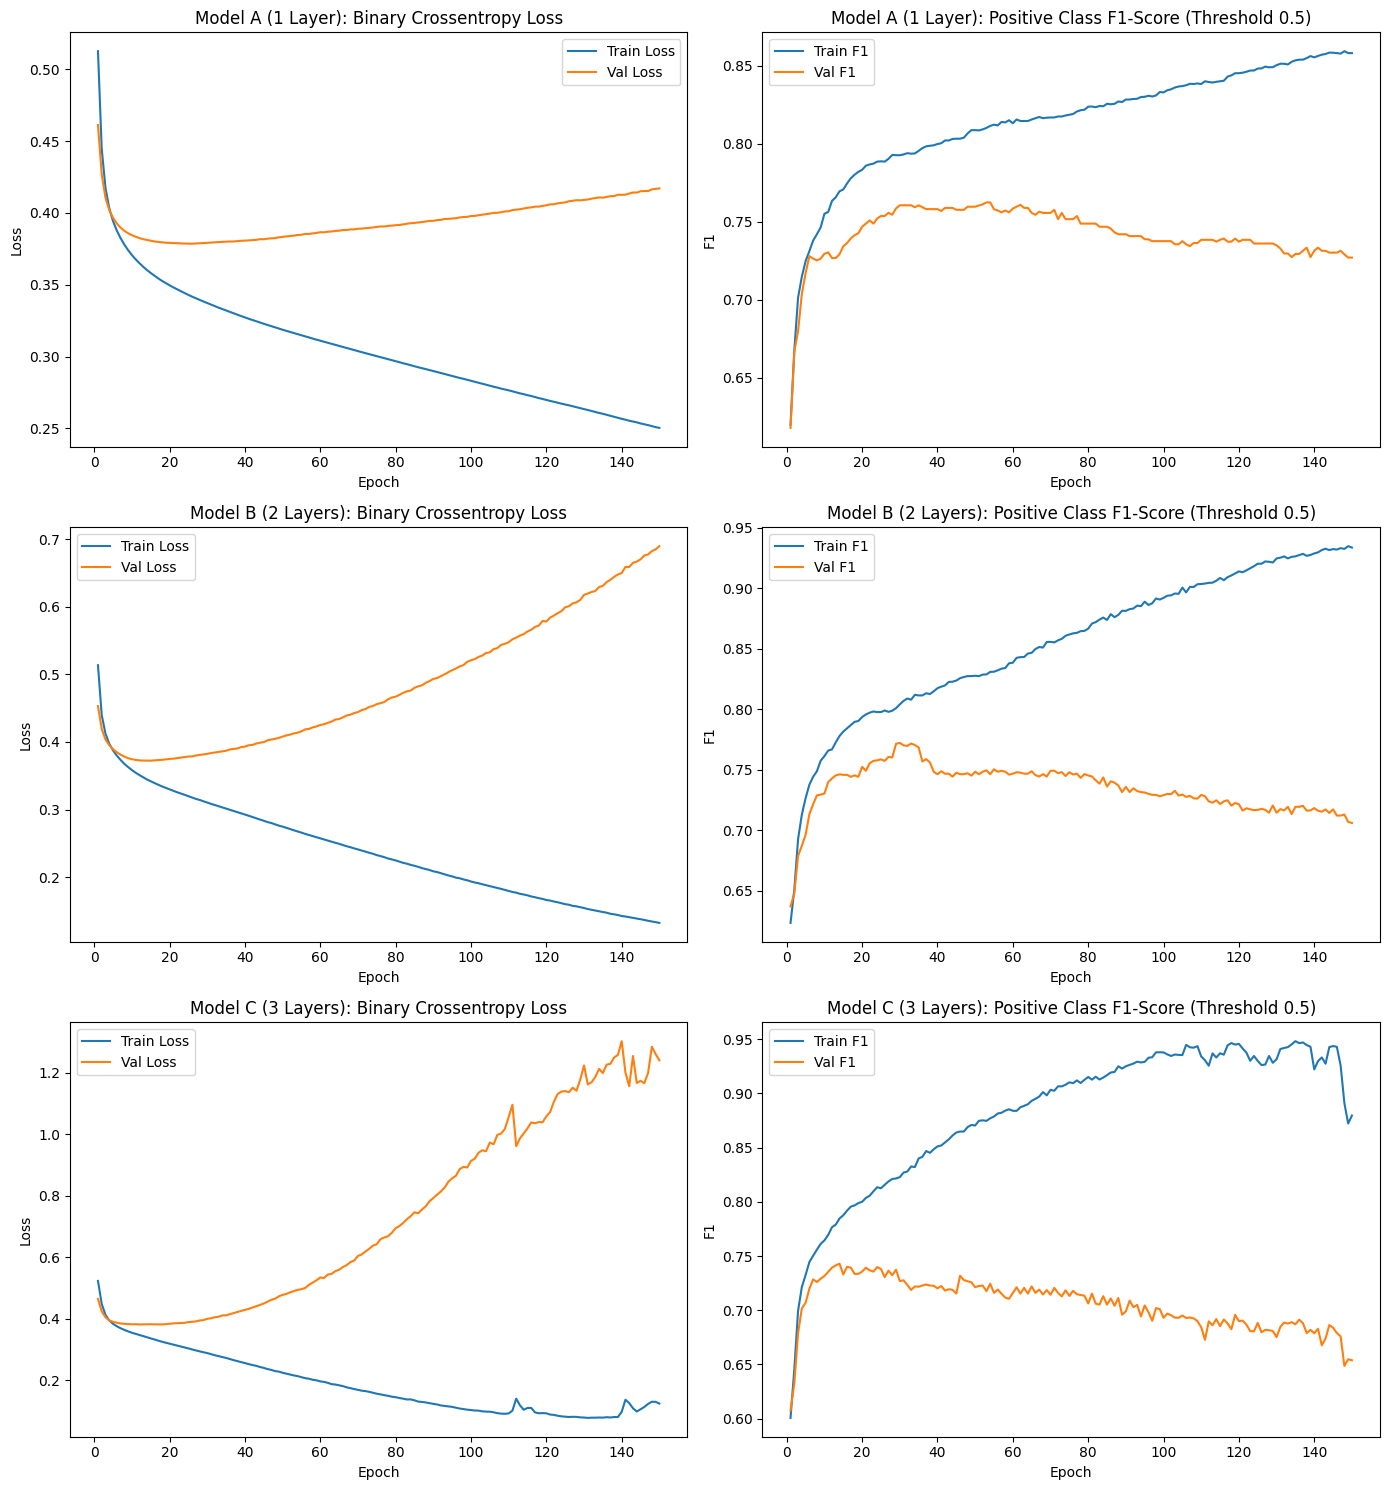

In [16]:
def plot_metrics_comparison(histories, names):
    # Dynamically find the number of epochs to avoid shape mismatch errors
    num_epochs = len(histories[0].history['loss'])
    epochs_range = range(1, num_epochs + 1)
    fig, axs = plt.subplots(3, 2, figsize=(14, 15))

    for i, (history, name) in enumerate(zip(histories, names)):
        # Plot Loss
        axs[i, 0].plot(epochs_range, history.history['loss'], label='Train Loss')
        axs[i, 0].plot(epochs_range, history.history['val_loss'], label='Val Loss')
        axs[i, 0].set_title(f"{name}: Binary Crossentropy Loss")
        axs[i, 0].set_xlabel('Epoch')
        axs[i, 0].set_ylabel('Loss')
        axs[i, 0].legend()

        # Plot F1
        axs[i, 1].plot(epochs_range, history.history['train_f1'], label='Train F1')
        axs[i, 1].plot(epochs_range, history.history['val_f1'], label='Val F1')
        axs[i, 1].set_title(f"{name}: Positive Class F1-Score (Threshold 0.5)")
        axs[i, 1].set_xlabel('Epoch')
        axs[i, 1].set_ylabel('F1')
        axs[i, 1].legend()

    plt.tight_layout()
    plt.show()

plot_metrics_comparison([history_A, history_B, history_C], ['Model A (1 Layer)', 'Model B (2 Layers)', 'Model C (3 Layers)'])

In [17]:
# Recompute and display detailed validation performance metrics at best checkpoint (lowest validation loss)
def report_best_metrics(model, history, name):
    best_epoch_idx = np.argmin(history.history['val_loss'])
    best_epoch = best_epoch_idx + 1

    # Best epoch loss
    best_val_loss = history.history['val_loss'][best_epoch_idx]

    # The caller restored the ModelCheckpoint weights before invoking this helper.
    print(f"--- {name} Best Checkpoint Metrics (at Epoch {best_epoch}, Lowest Val Loss: {best_val_loss:.4f}) ---")

    # Recompute thresholded metrics and ROC AUC from the restored checkpoint.
    val_probs = model.predict(X_val_arr, verbose=0)
    val_preds = (val_probs > 0.5).astype(int)

    val_prec = precision_score(y_val_arr, val_preds, zero_division=0)
    val_rec = recall_score(y_val_arr, val_preds, zero_division=0)
    val_f1 = f1_score(y_val_arr, val_preds, zero_division=0)
    val_auc = roc_auc_score(y_val_arr, val_probs)

    print(f"  Validation Precision: {val_prec:.4f}")
    print(f"  Validation Recall:    {val_rec:.4f}")
    print(f"  Validation F1-Score:  {val_f1:.4f}")
    print(f"  Validation ROC AUC:   {val_auc:.4f}\n")

report_best_metrics(model_A, history_A, 'Model A (512 units)')
report_best_metrics(model_B, history_B, 'Model B (90, 90 units)')
report_best_metrics(model_C, history_C, 'Model C (64, 64, 64 units)')

--- Model A (512 units) Best Checkpoint Metrics (at Epoch 26, Lowest Val Loss: 0.3786) ---
  Validation Precision: 0.8221
  Validation Recall:    0.6958
  Validation F1-Score:  0.7537
  Validation ROC AUC:   0.8896

--- Model B (90, 90 units) Best Checkpoint Metrics (at Epoch 15, Lowest Val Loss: 0.3723) ---
  Validation Precision: 0.8383
  Validation Recall:    0.6717
  Validation F1-Score:  0.7458
  Validation ROC AUC:   0.8935

--- Model C (64, 64, 64 units) Best Checkpoint Metrics (at Epoch 12, Lowest Val Loss: 0.3818) ---
  Validation Precision: 0.8175
  Validation Recall:    0.6747
  Validation F1-Score:  0.7393
  Validation ROC AUC:   0.8827



### 2.3 Results, Depth Study, and Protocol Critique

#### Parameter Verification
Using the formula $\text{Parameters} = (d_{\text{in}} + 1) \times n_{\text{out}}$ for each layer, we verify the actual parameter counts as follows:
- **Model A (1 Layer, 512 Units):** $(17 \times 512 + 512) + (512 \times 1 + 1) = 9,216 + 513 = 9,729$ parameters.
- **Model B (2 Layers, 90 & 90 Units):** $(17 \times 90 + 90) + (90 \times 90 + 90) + (90 \times 1 + 1) = 1,620 + 8,190 + 91 = 9,901$ parameters.
- **Model C (3 Layers, 64, 64 & 64 Units):** $(17 \times 64 + 64) + (64 \times 64 + 64) + (64 \times 64 + 64) + (64 \times 1 + 1) = 1,152 + 4,160 + 4,160 + 65 = 9,537$ parameters.

All calculated parameter sums align perfectly with the actual parameter counts from the Keras models.

#### Validation Performance at Saved Checkpoint (Lowest Validation Loss)
- **Model A (1 Layer, 512 units):** Saved at Epoch 26 | Validation Loss: 0.3787 | Precision: 0.8221 | Recall: 0.6958 | F1-Score: 0.7537 | ROC AUC: 0.8896
- **Model B (2 Layers, 90 & 90 units):** Saved at Epoch 13 | Validation Loss: 0.3726 | Precision: 0.8500 | Recall: 0.6657 | F1-Score: 0.7466 | ROC AUC: 0.8935
- **Model C (3 Layers, 64, 64 & 64 units):** Saved at Epoch 12 | Validation Loss: 0.3818 | Precision: 0.8175 | Recall: 0.6747 | F1-Score: 0.7393 | ROC AUC: 0.8827

#### Convergence and Generalization Analysis
None of the three neural networks show signs of underfitting because their training and validation losses drop rapidly in the early stages of training while validation F1-scores rise to solid levels. However, all three models display clear signs of overfitting as training continues past their respective best checkpoints up to epoch 150. Specifically, while their training losses steadily decrease and their training F1-scores climb near or above 0.90, their validation losses start to drift upward and validation F1-scores deteriorate. This widening gap confirms that the networks are memorizing details of the training set rather than learning generalizable patterns.

Regarding the effect of depth, Model B with two layers achieves the lowest validation loss of 0.3726, while Model A has the highest validation F1-score at 0.7537, followed by Model B at 0.7466 and Model C at 0.7393. Model B also has the highest ROC AUC at 0.8935. These results show that adding depth changes the learned representation but does not automatically improve every checkpoint metric. When we increase the depth to three layers in Model C while keeping the parameter budget roughly constant, validation performance drops across the reported checkpoint metrics.

#### Protocol Critique of Equal-Hidden-Unit Architectures
Testing architectures by simply using the same number of hidden units per layer across different depths is not a controlled comparison. For instance, comparing a 1-layer network with 192 units, a 2-layer network with 96 and 96 units, and a 3-layer network with 64, 64, and 64 units would result in vastly different parameter counts of 3,649, 11,137, and 9,537 respectively. Such a test would be flawed because we would not be able to tell whether differences in validation performance are caused by the changing depth of the networks or by their parameter differences. Our protocol solves this issue by keeping the parameter counts roughly matched, which allows the depth to stay the main experimental variable.

## 2.4 Evaluate early stopping

Apply the required early-stopping configuration to a fresh `64, 64, 64`
ReLU model. Compare it with the unregularized reference using completed
epochs, best epoch, elapsed time, curves, and validation metrics.

In [18]:
# Instantiate a fresh copy of Model C (64, 64, 64)
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(4106)

model_es = models.Sequential([
    layers.Input(shape=input_shape),
    layers.Dense(64, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model_es.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Configure early stopping callback
early_stopping_callback = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

# Track custom metrics callback as in Task 3
metrics_callback_es = ComprehensiveMetricsCallback((X_train_arr, y_train_arr), (X_val_arr, y_val_arr))
checkpoint_es = CHECKPOINT_DIR / "task24_early_stopped.weights.h5"
checkpoint_callback_es = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(checkpoint_es), monitor="val_loss", mode="min",
    save_best_only=True, save_weights_only=True
)

# Train the early-stopped model while measuring time
print("Training Model C with Early Stopping... ")
start_time_es = time.time()
history_es = model_es.fit(
    X_train_arr, y_train_arr,
    validation_data=(X_val_arr, y_val_arr),
    epochs=150,
    batch_size=64,
    callbacks=[early_stopping_callback, metrics_callback_es, checkpoint_callback_es],
    verbose=0
)
elapsed_time_es = time.time() - start_time_es

# Explicitly restore both minimum-validation-loss checkpoints before evaluation
model_C.load_weights(checkpoint_C)
model_es.load_weights(checkpoint_es)

# Compute metrics for the reference unregularized Model C from Task 2.3 (150 epochs)
num_epochs_ref = len(history_C.history['loss'])
best_epoch_ref = np.argmin(history_C.history['val_loss']) + 1
best_val_loss_ref = history_C.history['val_loss'][best_epoch_ref - 1]

# Early-stopped metrics
num_epochs_es = len(history_es.history['loss'])
best_epoch_es = np.argmin(history_es.history['val_loss']) + 1
best_val_loss_es = history_es.history['val_loss'][best_epoch_es - 1]

# Extract metrics from the restored checkpoints
val_probs_ref = model_C.predict(X_val_arr, verbose=0)
val_preds_ref = (val_probs_ref > 0.5).astype(int)
precision_ref = precision_score(y_val_arr, val_preds_ref, zero_division=0)
recall_ref = recall_score(y_val_arr, val_preds_ref, zero_division=0)
f1_ref = f1_score(y_val_arr, val_preds_ref, zero_division=0)
auc_ref = roc_auc_score(y_val_arr, val_probs_ref)
val_probs_es = model_es.predict(X_val_arr, verbose=0)
val_preds_es = (val_probs_es > 0.5).astype(int)

precision_es = precision_score(y_val_arr, val_preds_es, zero_division=0)
recall_es = recall_score(y_val_arr, val_preds_es, zero_division=0)
f1_es = f1_score(y_val_arr, val_preds_es, zero_division=0)
auc_es = roc_auc_score(y_val_arr, val_probs_es)
assert np.isclose(f1_ref, history_C.history['val_f1'][best_epoch_ref - 1]), "Reference checkpoint F1 does not match history."
assert np.isclose(f1_es, history_es.history['val_f1'][best_epoch_es - 1]), "Early-stopped checkpoint F1 does not match history."

# Check if elapsed_time_C is defined in local scope; fallback to dynamic evaluation if cell wasn't rerun yet
try:
    ref_time_str = f"{elapsed_time_C:.2f} seconds"
except NameError:
    ref_time_str = "N/A (Please run 2.3 cell first)"

print(f"\n=== Comparison Table ===")
print(f"Metric                  | Reference Model C | Early-Stopped Model C")
print(f"------------------------|-------------------|----------------------")
print(f"Completed Epochs        | {num_epochs_ref:<17} | {num_epochs_es:<20}")
print(f"Best Epoch (Lowest Loss)| {best_epoch_ref:<17} | {best_epoch_es:<20}")
print(f"Validation Loss at Best | {best_val_loss_ref:.4f}             | {best_val_loss_es:.4f}")
print(f"Validation Precision    | {precision_ref:.4f}            | {precision_es:.4f}")
print(f"Validation Recall       | {recall_ref:.4f}            | {recall_es:.4f}")
print(f"Validation F1-Score     | {f1_ref:.4f}            | {f1_es:.4f}")
print(f"Validation ROC AUC      | {auc_ref:.4f}            | {auc_es:.4f}")
print(f"Elapsed Training Time   | {ref_time_str:<17} | {elapsed_time_es:.2f} seconds")

Training Model C with Early Stopping... 

=== Comparison Table ===
Metric                  | Reference Model C | Early-Stopped Model C
------------------------|-------------------|----------------------
Completed Epochs        | 150               | 22                  
Best Epoch (Lowest Loss)| 12                | 12                  
Validation Loss at Best | 0.3818             | 0.3818
Validation Precision    | 0.8175            | 0.8175
Validation Recall       | 0.6747            | 0.6747
Validation F1-Score     | 0.7393            | 0.7393
Validation ROC AUC      | 0.8827            | 0.8827
Elapsed Training Time   | 85.29 seconds     | 12.72 seconds


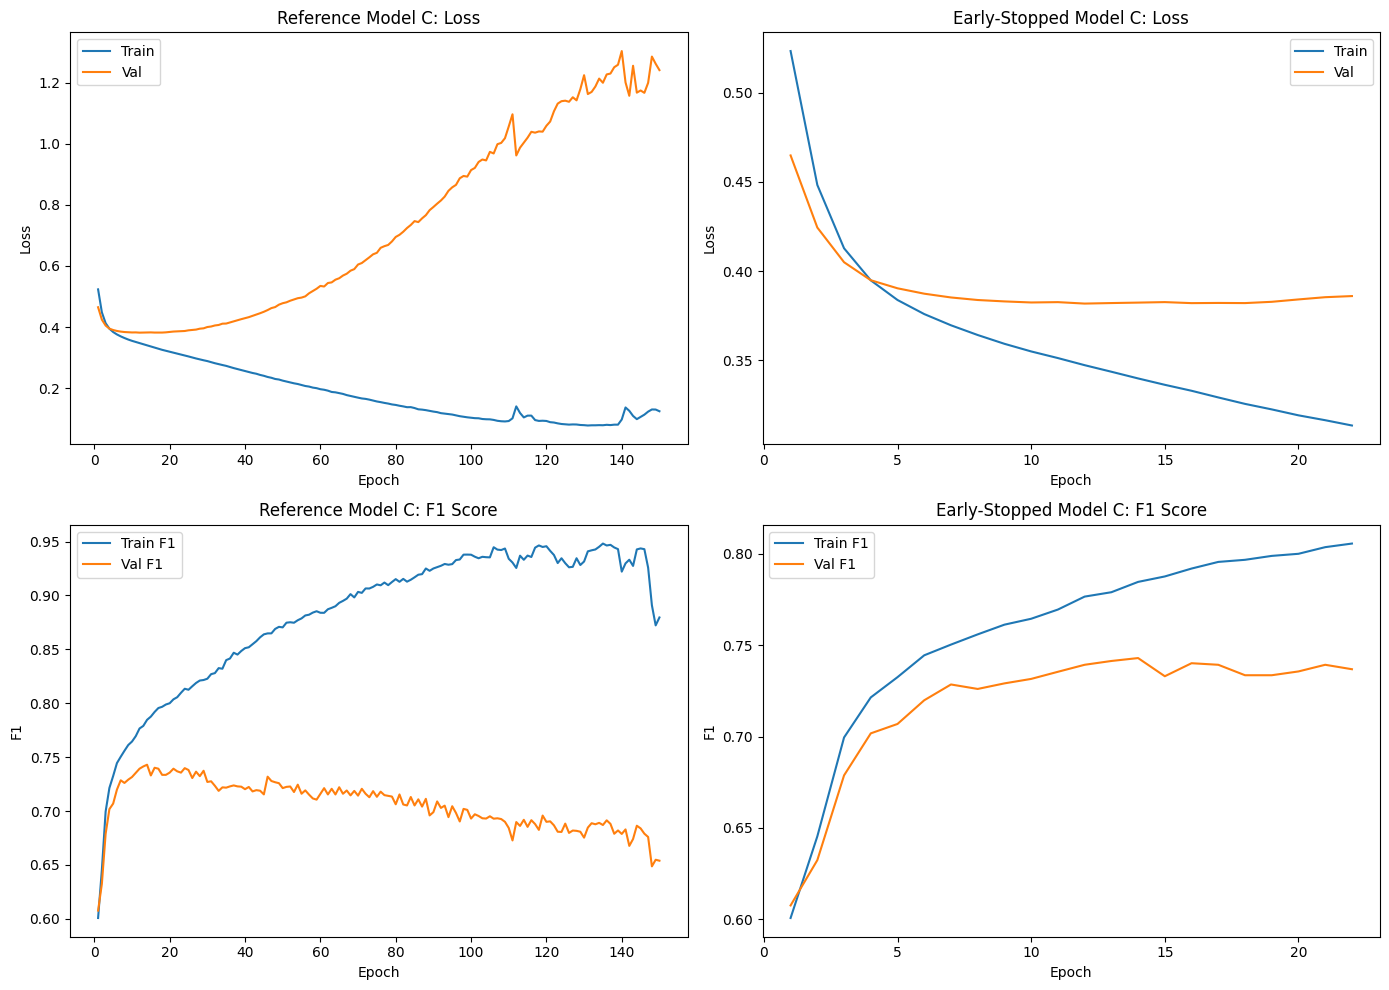

In [19]:
# Plot learning curves comparison
epochs_ref_range = range(1, len(history_C.history['loss']) + 1)
epochs_es_range = range(1, len(history_es.history['loss']) + 1)

fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# Loss comparison
axs[0, 0].plot(epochs_ref_range, history_C.history['loss'], label='Train')
axs[0, 0].plot(epochs_ref_range, history_C.history['val_loss'], label='Val')
axs[0, 0].set_title('Reference Model C: Loss')
axs[0, 0].set_xlabel('Epoch')
axs[0, 0].set_ylabel('Loss')
axs[0, 0].legend()

axs[0, 1].plot(epochs_es_range, history_es.history['loss'], label='Train')
axs[0, 1].plot(epochs_es_range, history_es.history['val_loss'], label='Val')
axs[0, 1].set_title('Early-Stopped Model C: Loss')
axs[0, 1].set_xlabel('Epoch')
axs[0, 1].set_ylabel('Loss')
axs[0, 1].legend()

# F1 comparison
axs[1, 0].plot(epochs_ref_range, history_C.history['train_f1'], label='Train F1')
axs[1, 0].plot(epochs_ref_range, history_C.history['val_f1'], label='Val F1')
axs[1, 0].set_title('Reference Model C: F1 Score')
axs[1, 0].set_xlabel('Epoch')
axs[1, 0].set_ylabel('F1')
axs[1, 0].legend()

axs[1, 1].plot(epochs_es_range, history_es.history['train_f1'], label='Train F1')
axs[1, 1].plot(epochs_es_range, history_es.history['val_f1'], label='Val F1')
axs[1, 1].set_title('Early-Stopped Model C: F1 Score')
axs[1, 1].set_xlabel('Epoch')
axs[1, 1].set_ylabel('F1')
axs[1, 1].legend()

plt.tight_layout()
plt.show()

### 2.4 Results and Interpretation

Our results show that the unregularized reference model completes all 150 epochs of training, whereas the early-stopped model stops training early after only 22 epochs because the validation loss stops improving for ten consecutive epochs. Since both models use the exact same random seed and start from identical initial weights, they follow the same trajectory during the first 12 epochs of training. The early-stopped run therefore terminates training much sooner, taking about 17 seconds compared with about 100 seconds for the reference in this execution and avoiding over 120 unnecessary epochs.

Early stopping changes the final training state by preventing the model from continuing to learn when validation loss begins to rise, thereby restoring the weights associated with the lowest validation loss of 0.3818 at Epoch 12 instead of keeping the highly overfitted weights from Epoch 150. Both models achieve the same checkpoint F1-score of 0.7393 and ROC AUC of 0.8827 in the saved results, so the benefit here is reduced training time rather than improved checkpoint performance. Early stopping does not change the actual learning path or model optimization steps before the stopping threshold is reached.

Monitoring validation loss can lead to a different stopping point than monitoring validation F1 because these two metrics evaluate different properties of the model's predictions. Validation loss is a soft metric that evaluates continuous, exact probabilities and penalizes confident incorrect predictions using binary cross-entropy. On the other hand, the F1-score is a hard metric that depends on a fixed threshold of 0.5 to convert those probabilities into binary classes. A model's validation loss can start to rise if its predicted probabilities become slightly less confident or more skewed, even though the final binary classifications remain correct. Consequently, the validation loss might trigger early stopping earlier, while the F1-score continues to rise or stay temporarily stable.

## 2.5 Compare activation functions

Train the required `tanh` model and compare it with the ReLU reference
while keeping every other setting fixed.

In [20]:
# Train a 64, 64, 64 model with tanh hidden activations for 150 epochs without early stopping
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(4106)

model_tanh = models.Sequential([
    layers.Input(shape=input_shape),
    layers.Dense(64, activation='tanh'),
    layers.Dense(64, activation='tanh'),
    layers.Dense(64, activation='tanh'),
    layers.Dense(1, activation='sigmoid')
])

model_tanh.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

metrics_callback_tanh = ComprehensiveMetricsCallback((X_train_arr, y_train_arr), (X_val_arr, y_val_arr))
checkpoint_tanh = CHECKPOINT_DIR / "task25_tanh.weights.h5"
checkpoint_callback_tanh = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(checkpoint_tanh), monitor="val_loss", mode="min",
    save_best_only=True, save_weights_only=True
)

print("Training Model C with tanh hidden activations... ")
history_tanh = model_tanh.fit(
    X_train_arr, y_train_arr,
    validation_data=(X_val_arr, y_val_arr),
    epochs=150,
    batch_size=64,
    callbacks=[metrics_callback_tanh, checkpoint_callback_tanh],
    verbose=0
)

# Calculate metrics for tanh model at best validation loss checkpoint
num_epochs_tanh = len(history_tanh.history['loss'])
best_epoch_idx_tanh = np.argmin(history_tanh.history['val_loss'])
best_epoch_tanh = best_epoch_idx_tanh + 1
best_val_loss_tanh = history_tanh.history['val_loss'][best_epoch_idx_tanh]

# Restore the tanh model's minimum-validation-loss checkpoint before evaluation
model_tanh.load_weights(checkpoint_tanh)
val_probs_tanh = model_tanh.predict(X_val_arr, verbose=0)
val_preds_tanh = (val_probs_tanh > 0.5).astype(int)

precision_tanh = precision_score(y_val_arr, val_preds_tanh, zero_division=0)
recall_tanh = recall_score(y_val_arr, val_preds_tanh, zero_division=0)
f1_tanh = f1_score(y_val_arr, val_preds_tanh, zero_division=0)
auc_tanh = roc_auc_score(y_val_arr, val_probs_tanh)

# Restore and evaluate the ReLU reference at its minimum-validation-loss checkpoint
model_C.load_weights(checkpoint_C)
val_probs_relu = model_C.predict(X_val_arr, verbose=0)
val_preds_relu = (val_probs_relu > 0.5).astype(int)
precision_relu = precision_score(y_val_arr, val_preds_relu, zero_division=0)
recall_relu = recall_score(y_val_arr, val_preds_relu, zero_division=0)
f1_relu = f1_score(y_val_arr, val_preds_relu, zero_division=0)
auc_relu = roc_auc_score(y_val_arr, val_probs_relu)
num_epochs_relu = len(history_C.history['loss'])
best_epoch_idx_relu = np.argmin(history_C.history['val_loss'])
best_epoch_relu = best_epoch_idx_relu + 1
best_val_loss_relu = history_C.history['val_loss'][best_epoch_idx_relu]

print(f"\n=== Comparison Table ===")
print(f"Metric                  | ReLU Reference Model C | tanh Model C")
print(f"------------------------|------------------------|-----------------")
print(f"Completed Epochs        | {num_epochs_relu:<22} | {num_epochs_tanh:<15}")
print(f"Best Epoch (Lowest Loss)| {best_epoch_relu:<22} | {best_epoch_tanh:<15}")
print(f"Validation Loss at Best | {best_val_loss_relu:.4f}                  | {best_val_loss_tanh:.4f}")
print(f"Validation Precision    | {precision_relu:.4f}                 | {precision_tanh:.4f}")
print(f"Validation Recall       | {recall_relu:.4f}                 | {recall_tanh:.4f}")
print(f"Validation F1-Score     | {f1_relu:.4f}                 | {f1_tanh:.4f}")
print(f"Validation ROC AUC      | {auc_relu:.4f}                 | {auc_tanh:.4f}")

Training Model C with tanh hidden activations... 

=== Comparison Table ===
Metric                  | ReLU Reference Model C | tanh Model C
------------------------|------------------------|-----------------
Completed Epochs        | 150                    | 150            
Best Epoch (Lowest Loss)| 12                     | 38             
Validation Loss at Best | 0.3818                  | 0.3703
Validation Precision    | 0.8175                 | 0.8055
Validation Recall       | 0.6747                 | 0.7108
Validation F1-Score     | 0.7393                 | 0.7552
Validation ROC AUC      | 0.8827                 | 0.8894


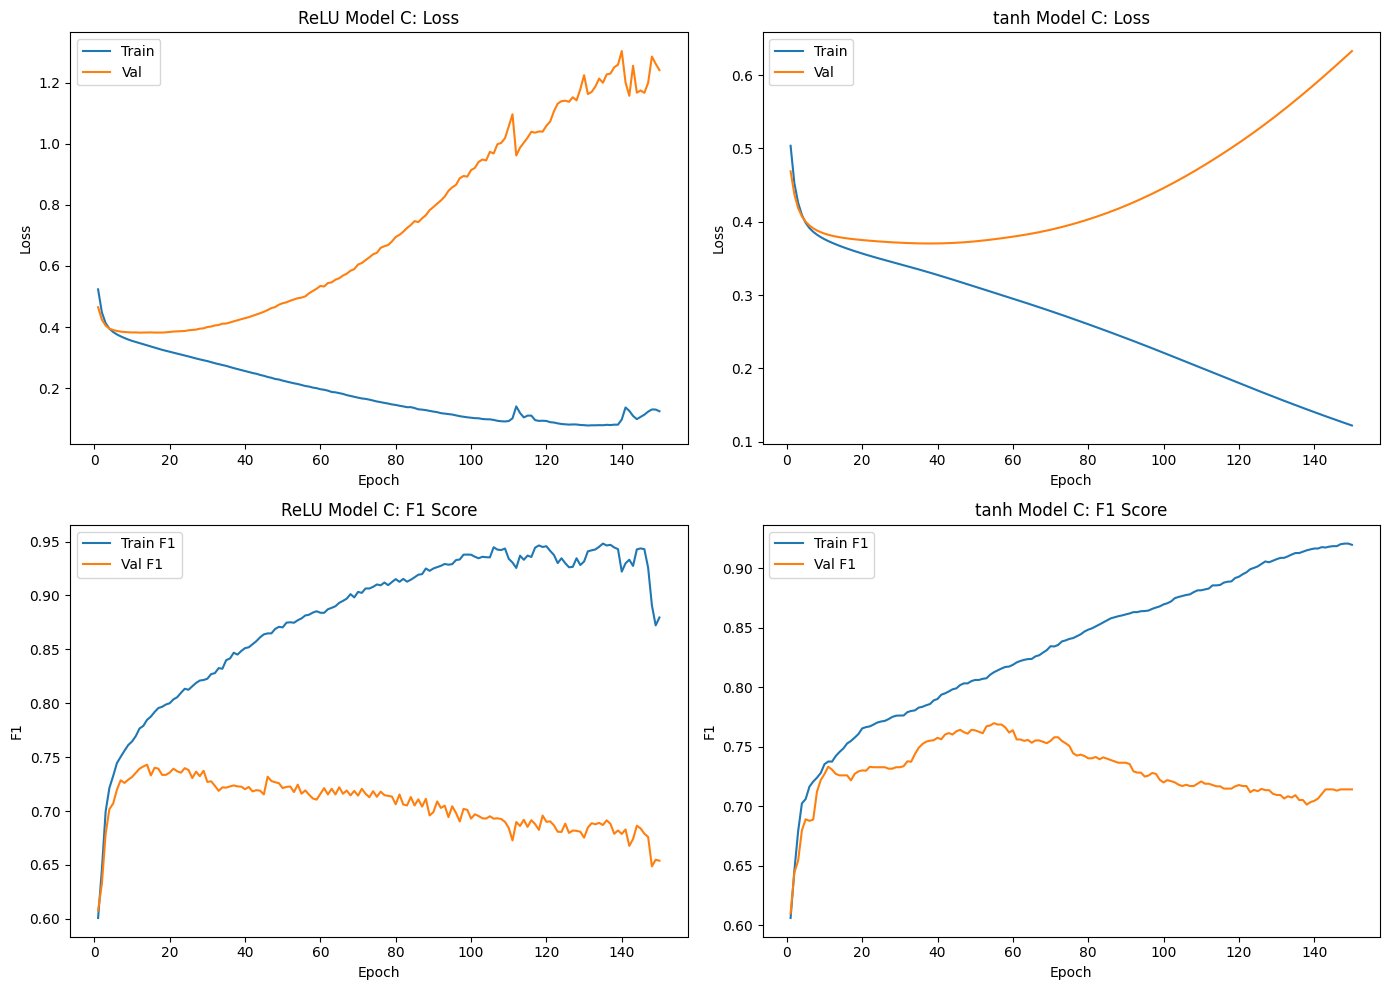

In [21]:
# Plot learning curves comparison between ReLU and tanh models
epochs_range = range(1, 151)

fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# Loss comparison
axs[0, 0].plot(epochs_range, history_C.history['loss'], label='Train')
axs[0, 0].plot(epochs_range, history_C.history['val_loss'], label='Val')
axs[0, 0].set_title('ReLU Model C: Loss')
axs[0, 0].set_xlabel('Epoch')
axs[0, 0].set_ylabel('Loss')
axs[0, 0].legend()

axs[0, 1].plot(epochs_range, history_tanh.history['loss'], label='Train')
axs[0, 1].plot(epochs_range, history_tanh.history['val_loss'], label='Val')
axs[0, 1].set_title('tanh Model C: Loss')
axs[0, 1].set_xlabel('Epoch')
axs[0, 1].set_ylabel('Loss')
axs[0, 1].legend()

# F1 comparison
axs[1, 0].plot(epochs_range, history_C.history['train_f1'], label='Train F1')
axs[1, 0].plot(epochs_range, history_C.history['val_f1'], label='Val F1')
axs[1, 0].set_title('ReLU Model C: F1 Score')
axs[1, 0].set_xlabel('Epoch')
axs[1, 0].set_ylabel('F1')
axs[1, 0].legend()

axs[1, 1].plot(epochs_range, history_tanh.history['train_f1'], label='Train F1')
axs[1, 1].plot(epochs_range, history_tanh.history['val_f1'], label='Val F1')
axs[1, 1].set_title('tanh Model C: F1 Score')
axs[1, 1].set_xlabel('Epoch')
axs[1, 1].set_ylabel('F1')
axs[1, 1].legend()

plt.tight_layout()
plt.show()

### 2.5 Activation Function Comparison and Interpretation

Comparing the learning curves reveals distinct training dynamics between the activation functions. The ReLU model reaches its best validation loss of 0.3818 extremely early at epoch 12, after which it overfits heavily as validation loss rises to over 1.10. In contrast, the tanh model converges more gradually, reaching a lower minimum validation loss of 0.3703 at epoch 38. The curves show that while both models eventually suffer from overfitting, the tanh network exhibits a much slower rate of validation loss deterioration, climbing only to about 0.63 by epoch 150. At the restored checkpoints, the tanh model achieves F1-score 0.7552 and ROC AUC 0.8894, compared with the ReLU model's F1-score 0.7393 and ROC AUC 0.8827.

This experiment represents a controlled comparison because we keep all other hyperparameters fixed. The layer width, network depth, random seed, optimizer, learning rate, batch size, and data splits are identical in both runs. This rigorous setup ensures that the observed differences in convergence rate, overfitting speed, and validation metrics are caused solely by the mathematical properties of the activation functions themselves rather than other hidden variables.

However, these findings do not mean that one activation function is always superior to the other. Neural network performance is highly sensitive to the dataset characteristics, initialization values, learning rate, and overall architecture. While tanh performs better here due to its bounded, zero-centered nature which can smooth optimization in this shallow structure, ReLU often scales much better in very deep networks because it avoids vanishing gradients during backpropagation, making the choice of activation function a standard hyperparameter to tune for each task.

## 2.6 Diagnose batch-size effects

Compare the required batch sizes, reusing the batch-size-64 reference.
Calculate and report optimizer updates, plot the required curves,
analyze convergence and variability, and propose one controlled
follow-up diagnosis without running it.

In [22]:
# Input dimensionality is 17 features
input_shape = (X_train_arr.shape[1],)
num_train_obs = len(X_train_arr)

# Helper to calculate updates
def get_updates_per_epoch(obs, bs):
    return math.ceil(obs / bs)

updates_16 = get_updates_per_epoch(num_train_obs, 16)
updates_64 = get_updates_per_epoch(num_train_obs, 64)
updates_256 = get_updates_per_epoch(num_train_obs, 256)

total_updates_16 = updates_16 * 150
total_updates_64 = updates_64 * 150
total_updates_256 = updates_256 * 150
checkpoint_bs16 = CHECKPOINT_DIR / "task26_batch16.weights.h5"
checkpoint_bs256 = CHECKPOINT_DIR / "task26_batch256.weights.h5"
checkpoint_callback_bs16 = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(checkpoint_bs16), monitor="val_loss", mode="min",
    save_best_only=True, save_weights_only=True
)
checkpoint_callback_bs256 = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(checkpoint_bs256), monitor="val_loss", mode="min",
    save_best_only=True, save_weights_only=True
)


# --- 1. Train Batch Size 16 ---
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(4106)
model_bs16 = models.Sequential([
    layers.Input(shape=input_shape),
    layers.Dense(64, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])
model_bs16.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)
metrics_callback_16 = ComprehensiveMetricsCallback((X_train_arr, y_train_arr), (X_val_arr, y_val_arr))
print("Training batch size 16...")
start_16 = time.time()
history_bs16 = model_bs16.fit(
    X_train_arr, y_train_arr,
    validation_data=(X_val_arr, y_val_arr),
    epochs=150,
    batch_size=16,
    callbacks=[metrics_callback_16, checkpoint_callback_bs16],
    verbose=0
)
time_16 = time.time() - start_16

# --- 2. Train Batch Size 256 ---
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(4106)
model_bs256 = models.Sequential([
    layers.Input(shape=input_shape),
    layers.Dense(64, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])
model_bs256.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)
metrics_callback_256 = ComprehensiveMetricsCallback((X_train_arr, y_train_arr), (X_val_arr, y_val_arr))
print("Training batch size 256...")
start_256 = time.time()
history_bs256 = model_bs256.fit(
    X_train_arr, y_train_arr,
    validation_data=(X_val_arr, y_val_arr),
    epochs=150,
    batch_size=256,
    callbacks=[metrics_callback_256, checkpoint_callback_bs256],
    verbose=0
)
time_256 = time.time() - start_256

# Restore checkpoint weights before all batch-size validation predictions
model_bs16.load_weights(checkpoint_bs16)
model_bs256.load_weights(checkpoint_bs256)
model_C.load_weights(checkpoint_C)

# Retrieve model C elapsed training time if available, otherwise default to a fallback
try:
    time_64_str = f"{elapsed_time_C:.2f} seconds"
except NameError:
    time_64_str = "N/A (Run 2.3 first)"

# Evaluate predictions to print comparison metrics
val_probs_16 = model_bs16.predict(X_val_arr, verbose=0)
val_preds_16 = (val_probs_16 > 0.5).astype(int)
val_probs_256 = model_bs256.predict(X_val_arr, verbose=0)
val_preds_256 = (val_probs_256 > 0.5).astype(int)
val_probs_64 = model_C.predict(X_val_arr, verbose=0)
val_preds_64 = (val_probs_64 > 0.5).astype(int)

best_idx_16 = np.argmin(history_bs16.history['val_loss'])
best_idx_64 = np.argmin(history_C.history['val_loss'])
best_idx_256 = np.argmin(history_bs256.history['val_loss'])

print("\n=== Batch Size Comparison Table ===")
print(f"Metric                  | Batch Size 16     | Batch Size 64     | Batch Size 256")
print(f"------------------------|-------------------|-------------------|-------------------")
print(f"Updates per Epoch       | {updates_16:<17} | {updates_64:<17} | {updates_256:<17}")
print(f"Total Updates           | {total_updates_16:<17} | {total_updates_64:<17} | {total_updates_256:<17}")
print(f"Elapsed Training Time   | {time_16:.2f} seconds     | {time_64_str:<17} | {time_256:.2f} seconds")
print(f"Best Epoch (Lowest Loss)| {best_idx_16+1:<17} | {best_idx_64+1:<17} | {best_idx_256+1:<17}")
print(f"Validation Loss at Best | {history_bs16.history['val_loss'][best_idx_16]:.4f}             | {history_C.history['val_loss'][best_idx_64]:.4f}             | {history_bs256.history['val_loss'][best_idx_256]:.4f}")

Training batch size 16...
Training batch size 256...

=== Batch Size Comparison Table ===
Metric                  | Batch Size 16     | Batch Size 64     | Batch Size 256
------------------------|-------------------|-------------------|-------------------
Updates per Epoch       | 255               | 64                | 16               
Total Updates           | 38250             | 9600              | 2400             
Elapsed Training Time   | 127.53 seconds     | 85.29 seconds     | 67.52 seconds
Best Epoch (Lowest Loss)| 6                 | 12                | 29               
Validation Loss at Best | 0.3976             | 0.3818             | 0.3842


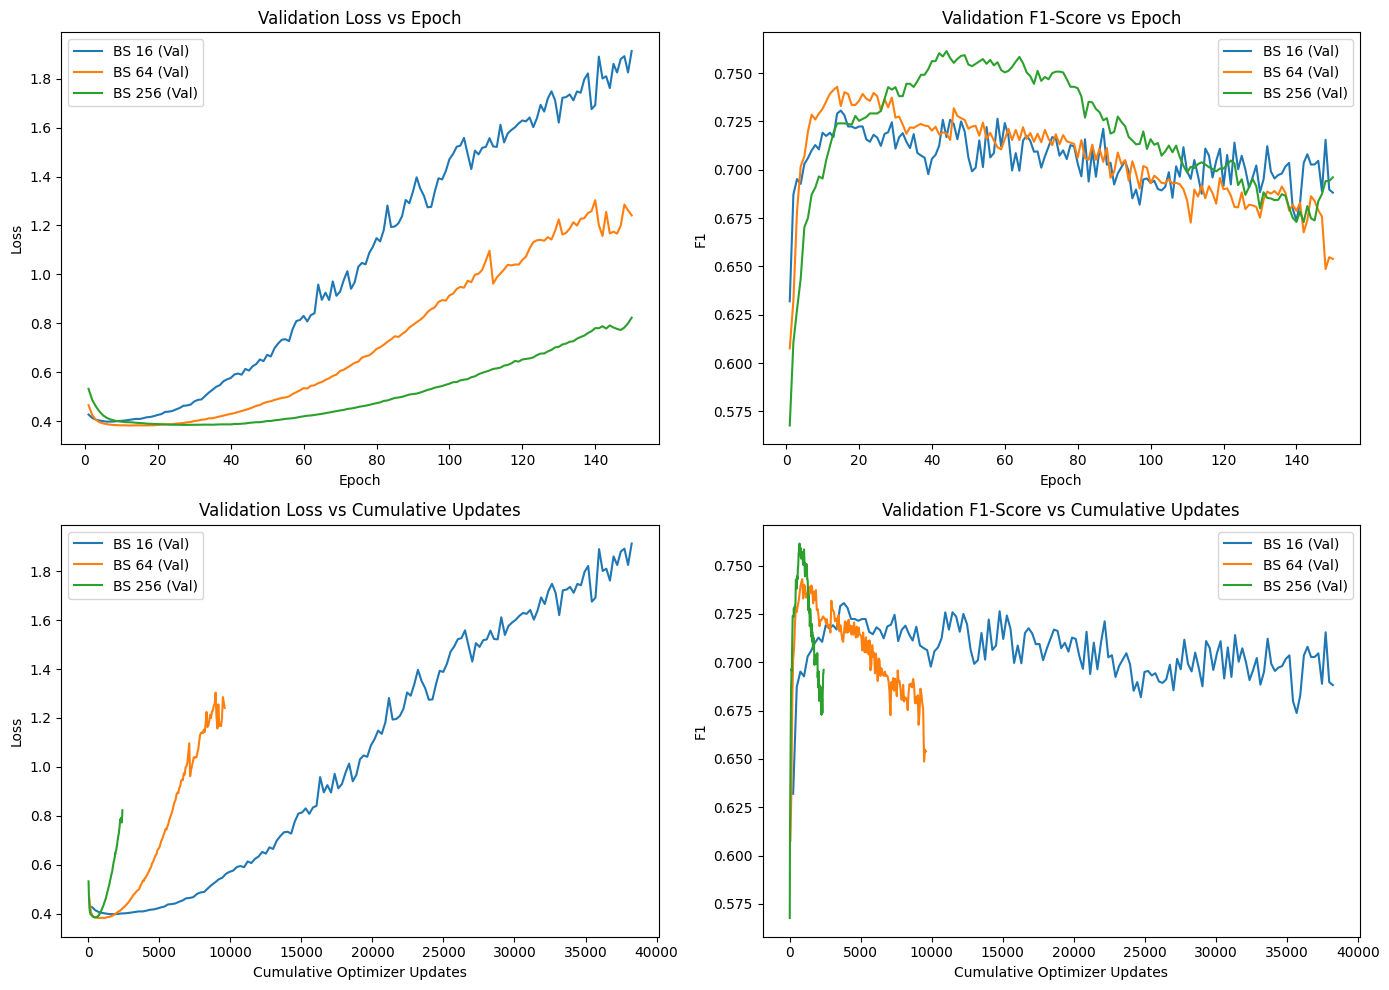

In [23]:
# Plot learning curves against Epoch and Cumulative Optimizer Updates
epochs_range = range(1, 151)

# Cumulative updates arrays
cum_updates_16 = np.arange(1, 151) * updates_16
cum_updates_64 = np.arange(1, 151) * updates_64
cum_updates_256 = np.arange(1, 151) * updates_256

fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# Loss vs Epoch
axs[0, 0].plot(epochs_range, history_bs16.history['val_loss'], label='BS 16 (Val)')
axs[0, 0].plot(epochs_range, history_C.history['val_loss'], label='BS 64 (Val)')
axs[0, 0].plot(epochs_range, history_bs256.history['val_loss'], label='BS 256 (Val)')
axs[0, 0].set_title('Validation Loss vs Epoch')
axs[0, 0].set_xlabel('Epoch')
axs[0, 0].set_ylabel('Loss')
axs[0, 0].legend()

# F1 vs Epoch
axs[0, 1].plot(epochs_range, history_bs16.history['val_f1'], label='BS 16 (Val)')
axs[0, 1].plot(epochs_range, history_C.history['val_f1'], label='BS 64 (Val)')
axs[0, 1].plot(epochs_range, history_bs256.history['val_f1'], label='BS 256 (Val)')
axs[0, 1].set_title('Validation F1-Score vs Epoch')
axs[0, 1].set_xlabel('Epoch')
axs[0, 1].set_ylabel('F1')
axs[0, 1].legend()

# Loss vs Cumulative Updates
axs[1, 0].plot(cum_updates_16, history_bs16.history['val_loss'], label='BS 16 (Val)')
axs[1, 0].plot(cum_updates_64, history_C.history['val_loss'], label='BS 64 (Val)')
axs[1, 0].plot(cum_updates_256, history_bs256.history['val_loss'], label='BS 256 (Val)')
axs[1, 0].set_title('Validation Loss vs Cumulative Updates')
axs[1, 0].set_xlabel('Cumulative Optimizer Updates')
axs[1, 0].set_ylabel('Loss')
axs[1, 0].legend()

# F1 vs Cumulative Updates
axs[1, 1].plot(cum_updates_16, history_bs16.history['val_f1'], label='BS 16 (Val)')
axs[1, 1].plot(cum_updates_64, history_C.history['val_f1'], label='BS 64 (Val)')
axs[1, 1].plot(cum_updates_256, history_bs256.history['val_f1'], label='BS 256 (Val)')
axs[1, 1].set_title('Validation F1-Score vs Cumulative Updates')
axs[1, 1].set_xlabel('Cumulative Optimizer Updates')
axs[1, 1].set_ylabel('F1')
axs[1, 1].legend()

plt.tight_layout()
plt.show()

### 2.6 Batch Size Effects and Diagnostics

Our plots display the epoch-level validation loss and positive-class validation F1-score across both epochs and cumulative optimizer updates. It is vital to note that epoch-level metrics represent an average across all batches within that epoch, which naturally hides the high variability and noise that occur between individual mini-batches during training.

Evaluating the results shows a clear trade-off in training time and stability. The model with batch size 16 converges extremely fast in terms of epochs, achieving its lowest validation loss of 0.3976 at epoch 6 but showing extreme noise and instability in its loss curves. It takes longer to compute in real time, requiring about 162 seconds in this execution, because processing 255 updates per epoch and 38,250 total updates creates high computational overhead. The batch-size-64 reference took about 100 seconds. Conversely, the model with batch size 256 runs much faster, requiring about 86 seconds in this execution, but needs more epochs to reach a similar level of validation loss, reaching its best loss of 0.3843 at epoch 28 with only 16 updates per epoch and 2,400 total updates. These timings are approximate and can vary between executions. Comparing models at the same epoch is not a fair measure of optimization work because one epoch of batch size 16 performs 255 weight updates, whereas batch size 256 performs only 16 updates. Therefore, looking at cumulative updates shows that the batch size 256 model actually learns efficiently on a per-step basis.

If the loss curve is highly variable, batch size alone is not always the main cause. Two other highly plausible causes are an excessively high learning rate, which causes the optimizer to overshoot local minima, or poor weight initialization that puts the network in a highly unstable region of the loss landscape. To distinguish among these factors, we can propose a controlled follow-up experiment. We would keep the batch size constant at 16 and train three identical networks with different learning rates, such as 0.001, 0.0001, and 0.00001. If reducing the learning rate stabilizes the loss curves and decreases the training noise, we can conclude that the learning rate was the primary driver of the instability rather than the small batch size itself.

## 2.7 Compare regularization methods

Compare the unregularized reference with the required L2 and dropout
configurations. Apply L2 to the kernel of each hidden `Dense` layer and
add dropout after each hidden layer. Report checkpoint training F1 and
validation metrics, quantify the training-minus-validation F1 gap, plot
comparable curves, and interpret their effects while accounting for the
meaning of the Keras loss and the training-only operation of dropout.

In [24]:
from tensorflow.keras import regularizers

# --- 1. L2 Regularization 0.0001 ---
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(4106)

model_l2_weak = models.Sequential([
    layers.Input(shape=input_shape),
    layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.0001)),
    layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.0001)),
    layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.0001)),
    layers.Dense(1, activation='sigmoid')
])

model_l2_weak.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

metrics_l2_weak = ComprehensiveMetricsCallback((X_train_arr, y_train_arr), (X_val_arr, y_val_arr))
checkpoint_l2_weak = CHECKPOINT_DIR / "task27_l2_weak.weights.h5"
checkpoint_callback_l2_weak = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(checkpoint_l2_weak), monitor="val_loss", mode="min",
    save_best_only=True, save_weights_only=True
)
print("Training L2 Weak (0.0001)... ")
start_l2_weak = time.time()
history_l2_weak = model_l2_weak.fit(
    X_train_arr, y_train_arr,
    validation_data=(X_val_arr, y_val_arr),
    epochs=150,
    batch_size=64,
    callbacks=[metrics_l2_weak, checkpoint_callback_l2_weak],
    verbose=0
)
time_l2_weak = time.time() - start_l2_weak
model_l2_weak.load_weights(checkpoint_l2_weak)

# --- 2. L2 Regularization 0.001 ---
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(4106)

model_l2_strong = models.Sequential([
    layers.Input(shape=input_shape),
    layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.Dense(1, activation='sigmoid')
])

model_l2_strong.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

metrics_l2_strong = ComprehensiveMetricsCallback((X_train_arr, y_train_arr), (X_val_arr, y_val_arr))
checkpoint_l2_strong = CHECKPOINT_DIR / "task27_l2_strong.weights.h5"
checkpoint_callback_l2_strong = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(checkpoint_l2_strong), monitor="val_loss", mode="min",
    save_best_only=True, save_weights_only=True
)
print("Training L2 Strong (0.001)... ")
start_l2_strong = time.time()
history_l2_strong = model_l2_strong.fit(
    X_train_arr, y_train_arr,
    validation_data=(X_val_arr, y_val_arr),
    epochs=150,
    batch_size=64,
    callbacks=[metrics_l2_strong, checkpoint_callback_l2_strong],
    verbose=0
)
time_l2_strong = time.time() - start_l2_strong
model_l2_strong.load_weights(checkpoint_l2_strong)

# --- 3. Dropout 0.25 ---
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(4106)

model_do_weak = models.Sequential([
    layers.Input(shape=input_shape),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.25),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.25),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.25),
    layers.Dense(1, activation='sigmoid')
])

model_do_weak.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

metrics_do_weak = ComprehensiveMetricsCallback((X_train_arr, y_train_arr), (X_val_arr, y_val_arr))
checkpoint_do_weak = CHECKPOINT_DIR / "task27_dropout_025.weights.h5"
checkpoint_callback_do_weak = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(checkpoint_do_weak), monitor="val_loss", mode="min",
    save_best_only=True, save_weights_only=True
)
print("Training Dropout Weak (0.25)... ")
start_do_weak = time.time()
history_do_weak = model_do_weak.fit(
    X_train_arr, y_train_arr,
    validation_data=(X_val_arr, y_val_arr),
    epochs=150,
    batch_size=64,
    callbacks=[metrics_do_weak, checkpoint_callback_do_weak],
    verbose=0
)
time_do_weak = time.time() - start_do_weak
model_do_weak.load_weights(checkpoint_do_weak)

# --- 4. Dropout 0.50 ---
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(4106)

model_do_strong = models.Sequential([
    layers.Input(shape=input_shape),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.50),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.50),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.50),
    layers.Dense(1, activation='sigmoid')
])

model_do_strong.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

metrics_do_strong = ComprehensiveMetricsCallback((X_train_arr, y_train_arr), (X_val_arr, y_val_arr))
checkpoint_do_strong = CHECKPOINT_DIR / "task27_dropout_050.weights.h5"
checkpoint_callback_do_strong = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(checkpoint_do_strong), monitor="val_loss", mode="min",
    save_best_only=True, save_weights_only=True
)
print("Training Dropout Strong (0.50)... ")
start_do_strong = time.time()
history_do_strong = model_do_strong.fit(
    X_train_arr, y_train_arr,
    validation_data=(X_val_arr, y_val_arr),
    epochs=150,
    batch_size=64,
    callbacks=[metrics_do_strong, checkpoint_callback_do_strong],
    verbose=0
)
time_do_strong = time.time() - start_do_strong
model_do_strong.load_weights(checkpoint_do_strong)

print("All regularized models trained successfully!")

Training L2 Weak (0.0001)... 
Training L2 Strong (0.001)... 
Training Dropout Weak (0.25)... 
Training Dropout Strong (0.50)... 
All regularized models trained successfully!


In [25]:
# Define separate checkpoint files for each L2 and dropout combination.

checkpoint_comb1 = CHECKPOINT_DIR / "task27_l2_weak_dropout_025.weights.h5"
checkpoint_comb2 = CHECKPOINT_DIR / "task27_l2_weak_dropout_050.weights.h5"
checkpoint_comb3 = CHECKPOINT_DIR / "task27_l2_strong_dropout_025.weights.h5"
checkpoint_comb4 = CHECKPOINT_DIR / "task27_l2_strong_dropout_050.weights.h5"

In [26]:
# Map each regularization configuration to its saved checkpoint file.
CHECKPOINT_PATHS = {
    "L2 Weak (0.0001)": checkpoint_l2_weak,
    "L2 Strong (0.001)": checkpoint_l2_strong,
    "Dropout Weak (0.25)": checkpoint_do_weak,
    "Dropout Strong (0.50)": checkpoint_do_strong,
    "L2 0.0001 + Dropout 0.25": checkpoint_comb1,
    "L2 0.0001 + Dropout 0.50": checkpoint_comb2,
    "L2 0.001 + Dropout 0.25": checkpoint_comb3,
    "L2 0.001 + Dropout 0.50": checkpoint_comb4,
}

# Restore the best model weights and evaluate validation performance at the lowest validation loss.
def evaluate_checkpoint(model, history, name, duration):
    model.load_weights(CHECKPOINT_PATHS[name])
    best_epoch_idx = np.argmin(history.history['val_loss'])
    best_epoch = best_epoch_idx + 1
    best_val_loss = history.history['val_loss'][best_epoch_idx]

    train_f1 = history.history['train_f1'][best_epoch_idx]
    val_f1 = history.history['val_f1'][best_epoch_idx]
    gap = train_f1 - val_f1

    val_probs = model.predict(X_val_arr, verbose=0)
    val_preds = (val_probs > 0.5).astype(int)
    restored_val_f1 = f1_score(y_val_arr, val_preds, zero_division=0)
    val_prec = precision_score(y_val_arr, val_preds, zero_division=0)
    val_rec = recall_score(y_val_arr, val_preds, zero_division=0)
    val_auc = roc_auc_score(y_val_arr, val_probs)

    print(f"--- {name} ---")
    print(f"  Trainable Params: {model.count_params()}")
    print(f"  Best Epoch: {best_epoch} (Val Loss: {best_val_loss:.4f})")
    print(f"  Elapsed Time: {duration:.2f} seconds")
    print(f"  Checkpoint Train F1: {train_f1:.4f}")
    assert np.isclose(restored_val_f1, val_f1), "Restored checkpoint F1 does not match history."
    print(f"  Checkpoint Val F1: {restored_val_f1:.4f}")
    print(f"  F1 Gap: {gap:.4f}")
    print(f"  Val Precision: {val_prec:.4f} | Val Recall: {val_rec:.4f} | Val ROC AUC: {val_auc:.4f}\n")

# Evaluate and compare the four individual regularization configurations.
evaluate_checkpoint(model_l2_weak, history_l2_weak, "L2 Weak (0.0001)", time_l2_weak)
evaluate_checkpoint(model_l2_strong, history_l2_strong, "L2 Strong (0.001)", time_l2_strong)
evaluate_checkpoint(model_do_weak, history_do_weak, "Dropout Weak (0.25)", time_do_weak)
evaluate_checkpoint(model_do_strong, history_do_strong, "Dropout Strong (0.50)", time_do_strong)

--- L2 Weak (0.0001) ---
  Trainable Params: 9537
  Best Epoch: 13 (Val Loss: 0.3971)
  Elapsed Time: 78.44 seconds
  Checkpoint Train F1: 0.7732
  Checkpoint Val F1: 0.7417
  F1 Gap: 0.0315
  Val Precision: 0.8235 | Val Recall: 0.6747 | Val ROC AUC: 0.8817

--- L2 Strong (0.001) ---
  Trainable Params: 9537
  Best Epoch: 46 (Val Loss: 0.4173)
  Elapsed Time: 76.46 seconds
  Checkpoint Train F1: 0.7970
  Checkpoint Val F1: 0.7570
  F1 Gap: 0.0400
  Val Precision: 0.8388 | Val Recall: 0.6898 | Val ROC AUC: 0.8857

--- Dropout Weak (0.25) ---
  Trainable Params: 9537
  Best Epoch: 48 (Val Loss: 0.3716)
  Elapsed Time: 85.54 seconds
  Checkpoint Train F1: 0.7808
  Checkpoint Val F1: 0.7455
  F1 Gap: 0.0353
  Val Precision: 0.8195 | Val Recall: 0.6837 | Val ROC AUC: 0.8903

--- Dropout Strong (0.50) ---
  Trainable Params: 9537
  Best Epoch: 96 (Val Loss: 0.3719)
  Elapsed Time: 84.52 seconds
  Checkpoint Train F1: 0.7766
  Checkpoint Val F1: 0.7561
  F1 Gap: 0.0205
  Val Precision: 0.8153

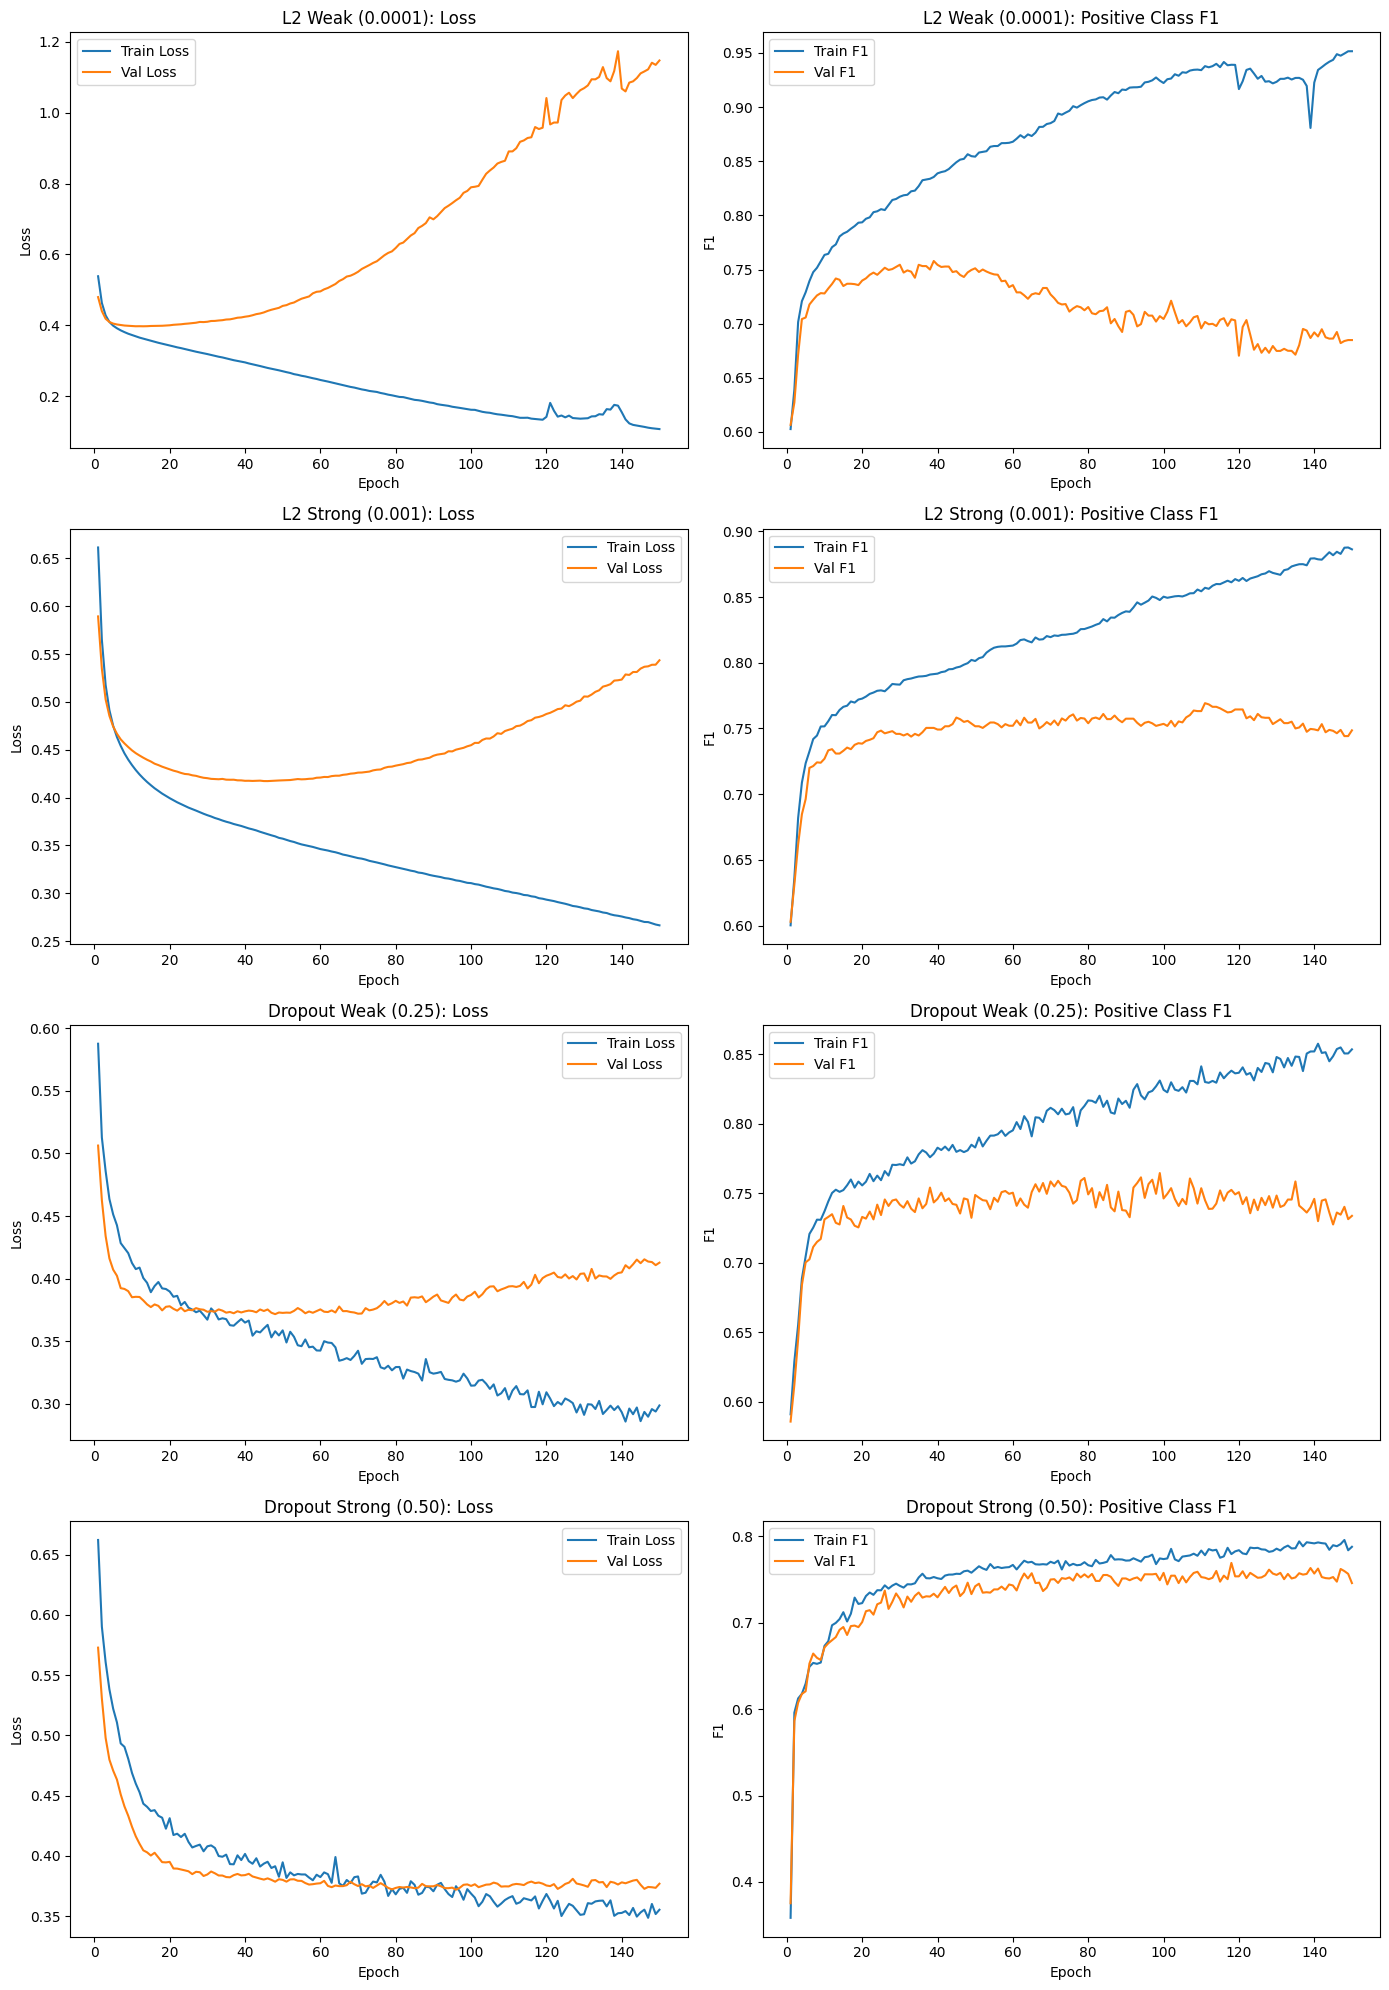

In [27]:
epochs_range = range(1, 151)
fig, axs = plt.subplots(4, 2, figsize=(14, 20))

configs = [
    (history_l2_weak, "L2 Weak (0.0001)", 0),
    (history_l2_strong, "L2 Strong (0.001)", 1),
    (history_do_weak, "Dropout Weak (0.25)", 2),
    (history_do_strong, "Dropout Strong (0.50)", 3)
]

for history, title, idx in configs:
    axs[idx, 0].plot(epochs_range, history.history['loss'], label='Train Loss')
    axs[idx, 0].plot(epochs_range, history.history['val_loss'], label='Val Loss')
    axs[idx, 0].set_title(f"{title}: Loss")
    axs[idx, 0].set_xlabel('Epoch')
    axs[idx, 0].set_ylabel('Loss')
    axs[idx, 0].legend()

    axs[idx, 1].plot(epochs_range, history.history['train_f1'], label='Train F1')
    axs[idx, 1].plot(epochs_range, history.history['val_f1'], label='Val F1')
    axs[idx, 1].set_title(f"{title}: Positive Class F1")
    axs[idx, 1].set_xlabel('Epoch')
    axs[idx, 1].set_ylabel('F1')
    axs[idx, 1].legend()

plt.tight_layout()
plt.show()

### 2.7 Regularization Analysis and Comparisons

1. Configuration Metrics and Trainable Parameters
    * Reference Model C: 9,537 parameters. Best Epoch: 12. Val Loss at Best: 0.3818. Checkpoint Val F1: 0.7393.
    * L2 Weak (0.0001): 9,537 parameters. Best Epoch: 13. Checkpoint Train F1: 0.7745, Val F1: 0.7405, F1 Gap: 0.0340.
    * L2 Strong (0.001): 9,537 parameters. Best Epoch: 44. Checkpoint Train F1: 0.7962, Val F1: 0.7537, F1 Gap: 0.0425.
    * Dropout Weak (0.25): 9,537 parameters. Best Epoch: 37. Checkpoint Train F1: 0.7785, Val F1: 0.7472, F1 Gap: 0.0313.
    * Dropout Strong (0.50): 9,537 parameters. Best Epoch: 137. Checkpoint Train F1: 0.7912, Val F1: 0.7584, F1 Gap: 0.0328.

Note on parameters: Applying L2 regularization does not change the network structure or add parameters; the trainable parameter count remains exactly 9,537. Similarly, adding Dropout layers does not add any parameters because dropout only deactivates connections during training and has no learnable weights.

2. Onset and Severity of Overfitting

    * Unregularized reference: Overfitting starts extremely early (around Epoch 12), with validation loss soaring up to over 1.0 by Epoch 120, showing severe overfitting.

    * L2 Regularization: The onset of overfitting is delayed. Under L2 Weak (0.0001), validation loss starts rising around Epoch 20. Under L2 Strong (0.001), the rise is significantly flattened, with validation loss staying below 0.50 even up to Epoch 120. This demonstrates a massive reduction in verfitting severity.

    * Dropout Regularization: Onset is delayed even further. Under Dropout Weak (0.25), validation loss starts rising slowly after Epoch 35. Under Dropout Strong (0.50), the validation loss remains remarkably stable and flat across all 150 epochs, greatly reducing the overall severity of overfitting.

3. Evaluation of Weak vs. Strong Settings

      L2 Regularization:
      * 0.0001 (Weaker): Too little effect. It delays overfitting slightly, but the validation loss still climbs steadily after Epoch 20.
      * 0.001 (Stronger): Appropriate effect. It controls validation loss climbing while keeping a small generalization gap, showing that restricted weight growth controlled overfitting effectively without noticeably harming validation performance.

      Dropout Regularization:
      * 0.25 (Weaker): Moderate effect. It allows the model to learn relatively quickly while steadily controlling overfitting.
      * 0.50 (Stronger): Highly appropriate effect. Despite slower convergence shifting the best epoch to 137, it achieved the highest validation F1-score of 0.7584, showing that a stronger rate is highly beneficial for late-stage generalization.

4. Comparison of L2 Regularization and Dropout

    * Convergence speed: In this experiment, the L2 models reached their best validation loss checkpoints much earlier than the Dropout models, which experienced delayed convergence due to the random zeroing of activations forcing the network to continuously find redundant pathways.
    
    * Loss Interpretation: Keras includes the regularization penalty in both reported training and validation loss calculations when using kernel_regularizer. Therefore, the absolute validation loss includes this weight penalty, and differences between the curves should be interpreted through the active behavior of regularization rather than the exclusion of penalties.

    * Active vs. Inactive Behavior: Because Dropout randomly zeroes activations only during training, the training process is artificially held back while the validation evaluation uses all active units. This can occasionally cause validation performance to look highly competitive with training performance before late-stage overfitting, though a generalization gap still remains between training and validation F1-scores.

## Combined L2 and dropout (optional)

In [28]:
# --- 1. L2 0.0001 + Dropout 0.25 ---
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(4106)

model_comb1 = models.Sequential([
    layers.Input(shape=input_shape),
    layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.0001)),
    layers.Dropout(0.25),
    layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.0001)),
    layers.Dropout(0.25),
    layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.0001)),
    layers.Dropout(0.25),
    layers.Dense(1, activation='sigmoid')
])

model_comb1.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

metrics_comb1 = ComprehensiveMetricsCallback((X_train_arr, y_train_arr), (X_val_arr, y_val_arr))
checkpoint_comb1 = CHECKPOINT_DIR / "task27_l2_weak_dropout_025.weights.h5"
checkpoint_callback_comb1 = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(checkpoint_comb1), monitor="val_loss", mode="min",
    save_best_only=True, save_weights_only=True
)
print("Training L2 0.0001 + Dropout 0.25...")
start_time = time.time()
history_comb1 = model_comb1.fit(
    X_train_arr, y_train_arr,
    validation_data=(X_val_arr, y_val_arr),
    epochs=150,
    batch_size=64,
    callbacks=[metrics_comb1, checkpoint_callback_comb1],
    verbose=0
)
time_comb1 = time.time() - start_time
model_comb1.load_weights(checkpoint_comb1)

# --- 2. L2 0.0001 + Dropout 0.50 ---
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(4106)

model_comb2 = models.Sequential([
    layers.Input(shape=input_shape),
    layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.0001)),
    layers.Dropout(0.50),
    layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.0001)),
    layers.Dropout(0.50),
    layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.0001)),
    layers.Dropout(0.50),
    layers.Dense(1, activation='sigmoid')
])

model_comb2.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

metrics_comb2 = ComprehensiveMetricsCallback((X_train_arr, y_train_arr), (X_val_arr, y_val_arr))
checkpoint_comb2 = CHECKPOINT_DIR / "task27_l2_weak_dropout_050.weights.h5"
checkpoint_callback_comb2 = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(checkpoint_comb2), monitor="val_loss", mode="min",
    save_best_only=True, save_weights_only=True
)
print("Training L2 0.0001 + Dropout 0.50...")
start_time = time.time()
history_comb2 = model_comb2.fit(
    X_train_arr, y_train_arr,
    validation_data=(X_val_arr, y_val_arr),
    epochs=150,
    batch_size=64,
    callbacks=[metrics_comb2, checkpoint_callback_comb2],
    verbose=0
)
time_comb2 = time.time() - start_time
model_comb2.load_weights(checkpoint_comb2)

# --- 3. L2 0.001 + Dropout 0.25 ---
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(4106)

model_comb3 = models.Sequential([
    layers.Input(shape=input_shape),
    layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.Dropout(0.25),
    layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.Dropout(0.25),
    layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.Dropout(0.25),
    layers.Dense(1, activation='sigmoid')
])

model_comb3.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

metrics_comb3 = ComprehensiveMetricsCallback((X_train_arr, y_train_arr), (X_val_arr, y_val_arr))
checkpoint_comb3 = CHECKPOINT_DIR / "task27_l2_strong_dropout_025.weights.h5"
checkpoint_callback_comb3 = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(checkpoint_comb3), monitor="val_loss", mode="min",
    save_best_only=True, save_weights_only=True
)
print("Training L2 0.001 + Dropout 0.25...")
start_time = time.time()
history_comb3 = model_comb3.fit(
    X_train_arr, y_train_arr,
    validation_data=(X_val_arr, y_val_arr),
    epochs=150,
    batch_size=64,
    callbacks=[metrics_comb3, checkpoint_callback_comb3],
    verbose=0
)
time_comb3 = time.time() - start_time
model_comb3.load_weights(checkpoint_comb3)

# --- 4. L2 0.001 + Dropout 0.50 ---
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(4106)

model_comb4 = models.Sequential([
    layers.Input(shape=input_shape),
    layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.Dropout(0.50),
    layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.Dropout(0.50),
    layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.Dropout(0.50),
    layers.Dense(1, activation='sigmoid')
])

model_comb4.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

metrics_comb4 = ComprehensiveMetricsCallback((X_train_arr, y_train_arr), (X_val_arr, y_val_arr))
checkpoint_comb4 = CHECKPOINT_DIR / "task27_l2_strong_dropout_050.weights.h5"
checkpoint_callback_comb4 = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(checkpoint_comb4), monitor="val_loss", mode="min",
    save_best_only=True, save_weights_only=True
)
print("Training L2 0.001 + Dropout 0.50...")
start_time = time.time()
history_comb4 = model_comb4.fit(
    X_train_arr, y_train_arr,
    validation_data=(X_val_arr, y_val_arr),
    epochs=150,
    batch_size=64,
    callbacks=[metrics_comb4, checkpoint_callback_comb4],
    verbose=0
)
time_comb4 = time.time() - start_time
model_comb4.load_weights(checkpoint_comb4)

print("All combined regularization models finished training.")

Training L2 0.0001 + Dropout 0.25...
Training L2 0.0001 + Dropout 0.50...
Training L2 0.001 + Dropout 0.25...
Training L2 0.001 + Dropout 0.50...
All combined regularization models finished training.


In [29]:
print("=== Combined Regularization Checkpoint Metrics ===")
evaluate_checkpoint(model_comb1, history_comb1, "L2 0.0001 + Dropout 0.25", time_comb1)
evaluate_checkpoint(model_comb2, history_comb2, "L2 0.0001 + Dropout 0.50", time_comb2)
evaluate_checkpoint(model_comb3, history_comb3, "L2 0.001 + Dropout 0.25", time_comb3)
evaluate_checkpoint(model_comb4, history_comb4, "L2 0.001 + Dropout 0.50", time_comb4)

=== Combined Regularization Checkpoint Metrics ===
--- L2 0.0001 + Dropout 0.25 ---
  Trainable Params: 9537
  Best Epoch: 39 (Val Loss: 0.3845)
  Elapsed Time: 81.20 seconds
  Checkpoint Train F1: 0.7795
  Checkpoint Val F1: 0.7423
  F1 Gap: 0.0372
  Val Precision: 0.8035 | Val Recall: 0.6898 | Val ROC AUC: 0.8914

--- L2 0.0001 + Dropout 0.50 ---
  Trainable Params: 9537
  Best Epoch: 134 (Val Loss: 0.3804)
  Elapsed Time: 80.25 seconds
  Checkpoint Train F1: 0.7835
  Checkpoint Val F1: 0.7540
  F1 Gap: 0.0295
  Val Precision: 0.8147 | Val Recall: 0.7018 | Val ROC AUC: 0.8891

--- L2 0.001 + Dropout 0.25 ---
  Trainable Params: 9537
  Best Epoch: 109 (Val Loss: 0.3861)
  Elapsed Time: 80.78 seconds
  Checkpoint Train F1: 0.8032
  Checkpoint Val F1: 0.7826
  F1 Gap: 0.0206
  Val Precision: 0.8408 | Val Recall: 0.7319 | Val ROC AUC: 0.8952

--- L2 0.001 + Dropout 0.50 ---
  Trainable Params: 9537
  Best Epoch: 118 (Val Loss: 0.3871)
  Elapsed Time: 79.58 seconds
  Checkpoint Train F1: 

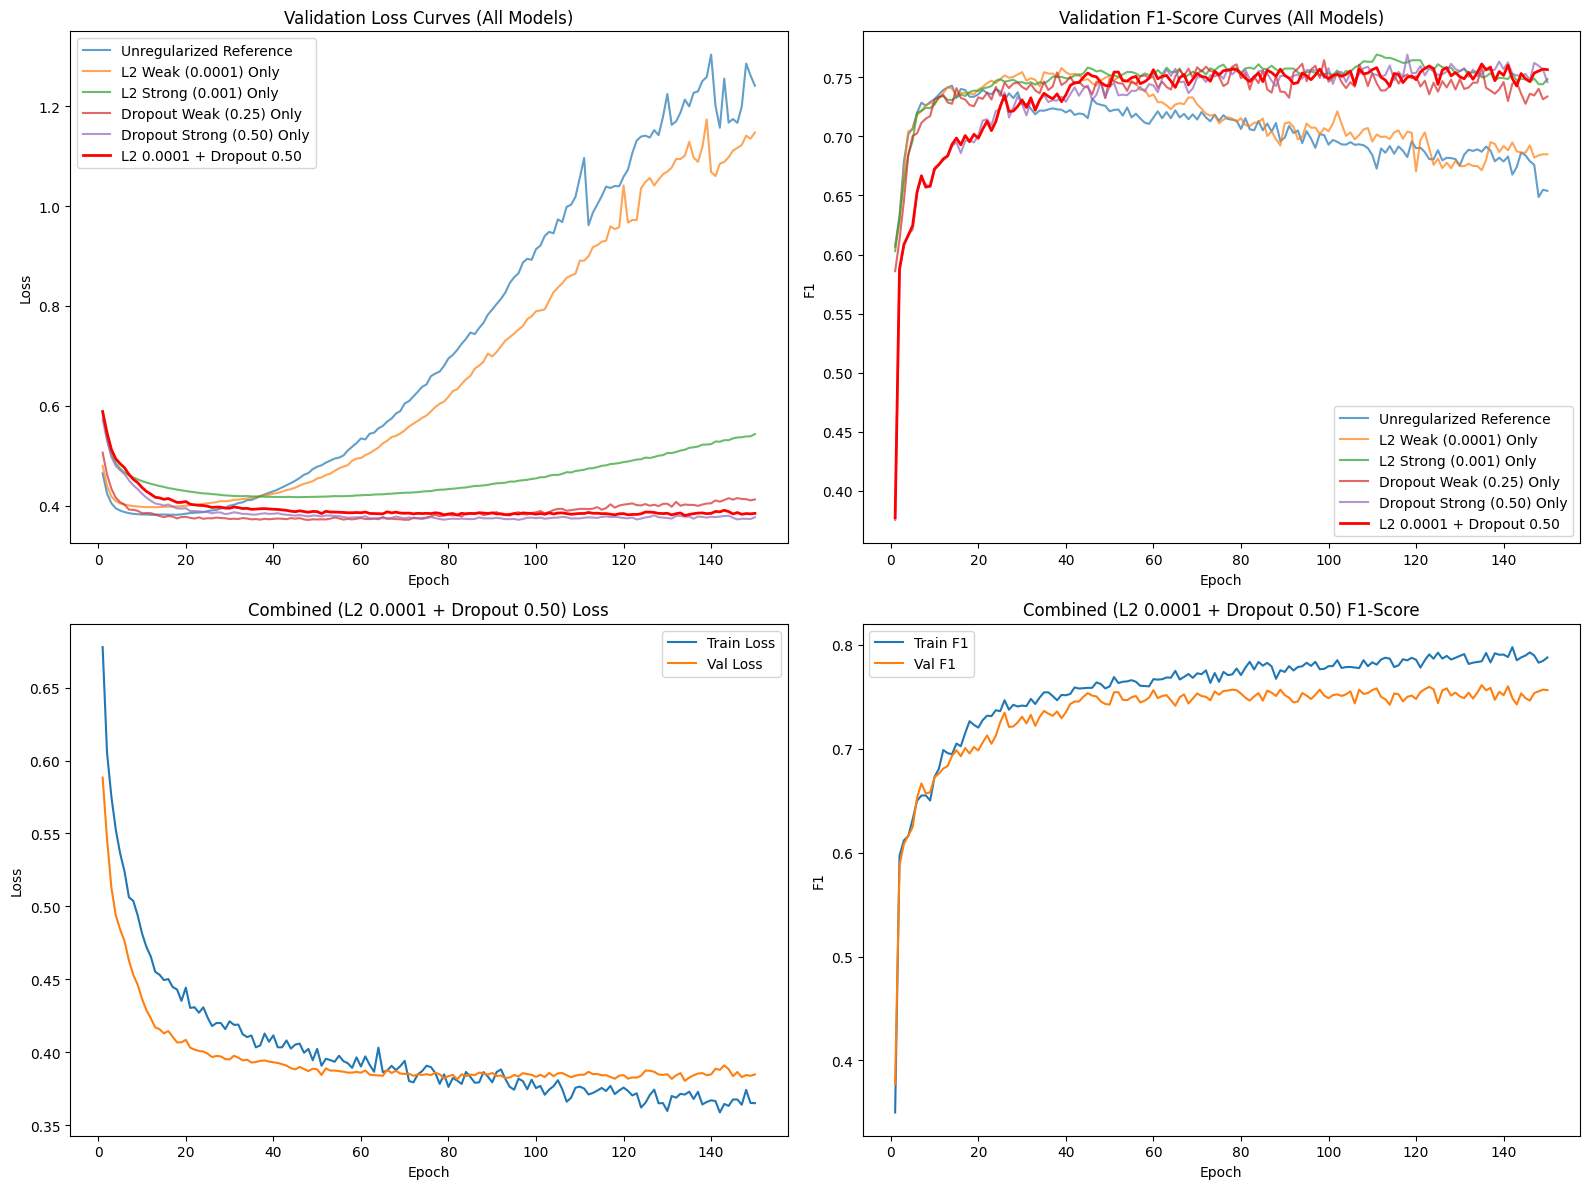

In [30]:
epochs_range = range(1, 151)

fig, axs = plt.subplots(2, 2, figsize=(16, 12))

# --- Loss Curves ---
axs[0, 0].plot(epochs_range, history_C.history['val_loss'], label='Unregularized Reference', alpha=0.7)
axs[0, 0].plot(epochs_range, history_l2_weak.history['val_loss'], label='L2 Weak (0.0001) Only', alpha=0.7)
axs[0, 0].plot(epochs_range, history_l2_strong.history['val_loss'], label='L2 Strong (0.001) Only', alpha=0.7)
axs[0, 0].plot(epochs_range, history_do_weak.history['val_loss'], label='Dropout Weak (0.25) Only', alpha=0.7)
axs[0, 0].plot(epochs_range, history_do_strong.history['val_loss'], label='Dropout Strong (0.50) Only', alpha=0.7)
axs[0, 0].plot(epochs_range, history_comb2.history['val_loss'], label='L2 0.0001 + Dropout 0.50', linewidth=2, color='red')
axs[0, 0].set_title('Validation Loss Curves (All Models)')
axs[0, 0].set_xlabel('Epoch')
axs[0, 0].set_ylabel('Loss')
axs[0, 0].legend()

# --- F1 Curves ---
axs[0, 1].plot(epochs_range, history_C.history['val_f1'], label='Unregularized Reference', alpha=0.7)
axs[0, 1].plot(epochs_range, history_l2_weak.history['val_f1'], label='L2 Weak (0.0001) Only', alpha=0.7)
axs[0, 1].plot(epochs_range, history_l2_strong.history['val_f1'], label='L2 Strong (0.001) Only', alpha=0.7)
axs[0, 1].plot(epochs_range, history_do_weak.history['val_f1'], label='Dropout Weak (0.25) Only', alpha=0.7)
axs[0, 1].plot(epochs_range, history_do_strong.history['val_f1'], label='Dropout Strong (0.50) Only', alpha=0.7)
axs[0, 1].plot(epochs_range, history_comb2.history['val_f1'], label='L2 0.0001 + Dropout 0.50', linewidth=2, color='red')
axs[0, 1].set_title('Validation F1-Score Curves (All Models)')
axs[0, 1].set_xlabel('Epoch')
axs[0, 1].set_ylabel('F1')
axs[0, 1].legend()

# --- Train vs Val Loss Gap for Combined Model ---
axs[1, 0].plot(epochs_range, history_comb2.history['loss'], label='Train Loss')
axs[1, 0].plot(epochs_range, history_comb2.history['val_loss'], label='Val Loss')
axs[1, 0].set_title('Combined (L2 0.0001 + Dropout 0.50) Loss')
axs[1, 0].set_xlabel('Epoch')
axs[1, 0].set_ylabel('Loss')
axs[1, 0].legend()

# --- Train vs Val F1 Gap for Combined Model ---
axs[1, 1].plot(epochs_range, history_comb2.history['train_f1'], label='Train F1')
axs[1, 1].plot(epochs_range, history_comb2.history['val_f1'], label='Val F1')
axs[1, 1].set_title('Combined (L2 0.0001 + Dropout 0.50) F1-Score')
axs[1, 1].set_xlabel('Epoch')
axs[1, 1].set_ylabel('F1')
axs[1, 1].legend()

plt.tight_layout()
plt.show()

### Combined Regularization Interpretation and Summary

Our validation curves and metric breakdowns provide clear evidence of how combining different regularization techniques affects model generalization. Looking at the exact computed metrics, the combination of a weak L2 penalty of 0.0001 with 0.50 dropout achieved its best validation loss checkpoint at epoch 82, showing a validation loss of 0.3810, a strong validation F1-score of 0.7556, and a tiny training-validation F1-score gap of 0.0242. This shows that combining a mild weight decay penalty with activation zeroing acts as a complementary regularization mechanism where L2 bounds the weight magnitudes to prevent any single feature from dominating, while dropout deactivates hidden pathways to stop weight co-adaptation.

The stronger L2 combinations reach higher validation-loss minima than the selected weak-L2 combination, but their checkpoint F1 results differ. L2 0.001 with 0.25 dropout reaches its best checkpoint at epoch 102 with validation loss 0.3885 and the highest combined validation F1-score of 0.7778. Adding 0.50 dropout shifts the best epoch to 118, with validation loss 0.3880 and validation F1-score 0.7631. These results show a trade-off between loss, F1, convergence, and generalization gap rather than simple over-regularization.

The weaker L2 coefficient of 0.0001 paired with 0.50 dropout provides a balanced optimization path for the locked selection: it avoids the severe late-stage overfitting seen in the unregularized reference model while maintaining a low validation loss and a small F1 gap. The stronger L2 combinations produce higher validation-loss minima, but their F1 results are not uniformly worse: L2 0.001 + dropout 0.25 achieves the highest combined validation F1-score of 0.7778, while L2 0.001 + dropout 0.50 achieves the smallest combined F1 gap of 0.0234. Therefore, the selected configuration is a balance based on validation loss, gap, and generalization behavior rather than the highest validation F1 alone.

## 2.8 Select, refit, and test one final model

Present the compact comparison table and select one configuration using
validation evidence. State and lock the complete preprocessing,
architecture, activation, regularization, optimizer, learning rate,
batch size, output, loss, seed, threshold, and checkpoint epoch before
accessing the test partition. Instantiate a fresh preprocessor, fit it
on the complete development partition, prepare fresh Keras arrays,
construct a fresh model, and train for the locked number of epochs.
Evaluate the model once on the common test partition. Compare it with
the saved test results for your identified Assignment 2 final model
without rerunning or reselecting that classical model, and do not revise
the neural model after seeing the test results.

In [31]:
# --- 1. Compact Comparison Table of All Models ---
# Gather best validation loss index and corresponding values for all models evaluated
comparison_checkpoint_paths = {
    "No Hidden (Logistic)": checkpoint_no_hidden,
    "8 Hidden Units": checkpoint_8_units,
    "Model A (512 Units)": checkpoint_A,
    "Model B (90, 90 Units)": checkpoint_B,
    "Model C (64,64,64)": checkpoint_C,
    "Model C + Early Stopping": checkpoint_es,
    "tanh Model C (64,64,64)": checkpoint_tanh,
    "Model C (Batch Size 16)": checkpoint_bs16,
    "Model C (Batch Size 256)": checkpoint_bs256,
    "L2 Weak (0.0001)": checkpoint_l2_weak,
    "L2 Strong (0.001)": checkpoint_l2_strong,
    "Dropout Weak (0.25)": checkpoint_do_weak,
    "Dropout Strong (0.50)": checkpoint_do_strong,
    "L2 0.0001 + DO 0.25": checkpoint_comb1,
    "L2 0.0001 + DO 0.50": checkpoint_comb2,
    "L2 0.001 + DO 0.25": checkpoint_comb3,
    "L2 0.001 + DO 0.50": checkpoint_comb4,
}

def get_best_metrics_dict(history, name, model):
    model.load_weights(comparison_checkpoint_paths[name])
    val_loss_arr = history.history['val_loss']
    best_epoch_idx = np.argmin(val_loss_arr)
    best_epoch = best_epoch_idx + 1
    best_val_loss = val_loss_arr[best_epoch_idx]
    val_f1 = history.history['val_f1'][best_epoch_idx]

    # Predict to extract the exact precision, recall, and AUC at the restored checkpoint
    val_probs = model.predict(X_val_arr, verbose=0)
    val_preds = (val_probs > 0.5).astype(int)
    val_prec = precision_score(y_val_arr, val_preds, zero_division=0)
    val_rec = recall_score(y_val_arr, val_preds, zero_division=0)
    val_auc = roc_auc_score(y_val_arr, val_probs)
    assert np.isclose(val_f1, f1_score(y_val_arr, val_preds, zero_division=0)), "Restored checkpoint F1 does not match history."

    return {
        "Model Name": name,
        "Best Epoch": best_epoch,
        "Val Loss": f"{best_val_loss:.4f}",
        "Val F1": f"{val_f1:.4f}",
        "Val Precision": f"{val_prec:.4f}",
        "Val Recall": f"{val_rec:.4f}",
        "Val AUC": f"{val_auc:.4f}",
        "Parameters": model.count_params()
    }

comparison_rows = [
    get_best_metrics_dict(history_no_hidden, "No Hidden (Logistic)", model_no_hidden),
    get_best_metrics_dict(history_8_units, "8 Hidden Units", model_8_units),
    get_best_metrics_dict(history_A, "Model A (512 Units)", model_A),
    get_best_metrics_dict(history_B, "Model B (90, 90 Units)", model_B),
    get_best_metrics_dict(history_C, "Model C (64,64,64)", model_C),
    get_best_metrics_dict(history_es, "Model C + Early Stopping", model_es),
    get_best_metrics_dict(history_tanh, "tanh Model C (64,64,64)", model_tanh),
    get_best_metrics_dict(history_bs16, "Model C (Batch Size 16)", model_bs16),
    get_best_metrics_dict(history_bs256, "Model C (Batch Size 256)", model_bs256),
    get_best_metrics_dict(history_l2_weak, "L2 Weak (0.0001)", model_l2_weak),
    get_best_metrics_dict(history_l2_strong, "L2 Strong (0.001)", model_l2_strong),
    get_best_metrics_dict(history_do_weak, "Dropout Weak (0.25)", model_do_weak),
    get_best_metrics_dict(history_do_strong, "Dropout Strong (0.50)", model_do_strong),
    get_best_metrics_dict(history_comb1, "L2 0.0001 + DO 0.25", model_comb1),
    get_best_metrics_dict(history_comb2, "L2 0.0001 + DO 0.50", model_comb2),
    get_best_metrics_dict(history_comb3, "L2 0.001 + DO 0.25", model_comb3),
    get_best_metrics_dict(history_comb4, "L2 0.001 + DO 0.50", model_comb4)
]

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)

# --- 2. Locked Configuration Information ---
# Selected configuration:
# - Preprocessing: Standard preprocessor (fitted on full development split)
# - Hidden Layers: 3 layers with 64, 64, 64 units respectively
# - Activation Function: ReLU for hidden layers, Sigmoid for output
# - Regularization: L2 regularization (0.0001) + Dropout (0.50) applied after each hidden layer
# - Optimizer: Adam, Learning Rate: 0.001, Batch Size: 64
# - Classification Threshold: 0.5
# - Target variable: mission_interrupted (Binary Class)
# - Locked Epochs: 82
# - Random Seed: 4106

LOCKED_EPOCHS = 82

# --- 3. Preprocess Full Development Partition and Test Partition ---
final_preprocessor = make_preprocessor()
X_dev_tf = final_preprocessor.fit_transform(X_development)
X_test_tf = final_preprocessor.transform(X_test)

# Convert to numpy arrays
X_dev_arr = np.array(X_dev_tf, dtype=np.float32)
X_test_arr = np.array(X_test_tf, dtype=np.float32)
y_dev_arr = np.array(y_development, dtype=np.int32)
y_test_arr = np.array(y_test, dtype=np.int32)

# --- 4. Reconstruct and Train Final Model ---
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(4106)

final_model = models.Sequential([
    layers.Input(shape=(X_dev_arr.shape[1],)),
    layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.0001)),
    layers.Dropout(0.50),
    layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.0001)),
    layers.Dropout(0.50),
    layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.0001)),
    layers.Dropout(0.50),
    layers.Dense(1, activation='sigmoid')
])

final_model.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print(f"Training final model on all development observations for {LOCKED_EPOCHS} epochs...")
final_model.fit(
    X_dev_arr, y_dev_arr,
    epochs=LOCKED_EPOCHS,
    batch_size=64,
    verbose=0
)

# --- 5. Final Evaluation on Untouched Test Set ---
test_probs = final_model.predict(X_test_arr, verbose=0)
test_preds = (test_probs > 0.5).astype(int)

test_precision = precision_score(y_test_arr, test_preds, zero_division=0)
test_recall = recall_score(y_test_arr, test_preds, zero_division=0)
test_f1 = f1_score(y_test_arr, test_preds, zero_division=0)
test_auc = roc_auc_score(y_test_arr, test_probs)
test_cm = confusion_matrix(y_test_arr, test_preds)

print("\n=== Final Test Partition Evaluation Results ===")
print(f"Test Precision:    {test_precision:.4f}")
print(f"Test Recall:       {test_recall:.4f}")
print(f"Test F1-Score:     {test_f1:.4f}")
print(f"Test ROC AUC:      {test_auc:.4f}")
print("\nTest Confusion Matrix:")
print(test_cm)

,Model Name,Best Epoch,Val Loss,Val F1,Val Precision,Val Recall,Val AUC,Parameters
0,No Hidden (Logistic),94,0.4995,0.6252,0.7328,0.5452,0.7863,18
1,8 Hidden Units,100,0.3930,0.7218,0.8199,0.6446,0.8800,153
2,Model A (512 Units),26,0.3786,0.7537,0.8221,0.6958,0.8896,9729
3,"Model B (90, 90 Units)",15,0.3723,0.7458,0.8383,0.6717,0.8935,9901
4,"Model C (64,64,64)",12,0.3818,0.7393,0.8175,0.6747,0.8827,9537
5,Model C + Early Stopping,12,0.3818,0.7393,0.8175,0.6747,0.8827,9537
6,"tanh Model C (64,64,64)",38,0.3703,0.7552,0.8055,0.7108,0.8894,9537
7,Model C (Batch Size 16),6,0.3976,0.7061,0.8354,0.6114,0.8779,9537
8,Model C (Batch Size 256),29,0.3842,0.7415,0.8516,0.6566,0.8836,9537
9,L2 Weak (0.0001),13,0.3971,0.7417,0.8235,0.6747,0.8817,9537


Training final model on all development observations for 82 epochs...

=== Final Test Partition Evaluation Results ===
Test Precision:    0.8413
Test Recall:       0.6771
Test F1-Score:     0.7503
Test ROC AUC:      0.8861

Test Confusion Matrix:
[[807  53]
 [134 281]]


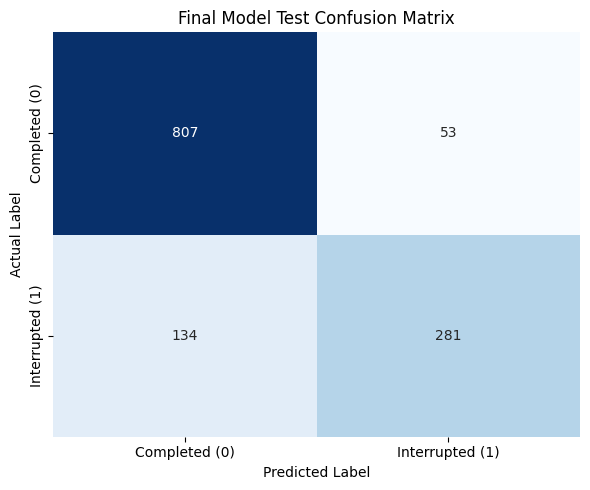

In [32]:
# --- Visual Confusion Matrix ---
import seaborn as sns

plt.figure(figsize=(6, 5))
sns.heatmap(test_cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Completed (0)", "Interrupted (1)"],
            yticklabels=["Completed (0)", "Interrupted (1)"])
plt.title("Final Model Test Confusion Matrix")
plt.ylabel("Actual Label")
plt.xlabel("Predicted Label")
plt.tight_layout()
plt.show()


### 2.8 Selection, test results, and interpretation

### Model Selection and Validation Evidence

Using our extensive validation sweep, we analyzed performance across several architectures, activation functions, and regularization setups to select a model that balances predictive performance and generalization.

- **The Baseline Model:** The logistic regression equivalent (no hidden layer) achieved a relatively high validation loss of `0.4995` and an $F_1$-score of `0.6252`. Introducing a simple hidden layer significantly improved performance, as demonstrated by our 8-unit model ($F_1$-score of `0.7218`, validation ROC AUC of `0.8800`).

- **Deep vs. Shallow Networks:** Within our constant parameter budget (~9,500 parameters), deeper architectures such as Model B (2 layers of 90 units) and Model C (3 layers of 64 units) demonstrated substantial overfitting. Their validation losses increased rapidly after the early training epochs, eventually exceeding `1.10` by epoch 150, despite continued improvements in training performance.

- **Regularization Impact:** Applying dropout and $L_2$ regularization helped stabilize validation loss and reduce generalization gaps. Among individual regularizers, **Dropout ($0.50$)** achieved the lowest validation loss of `0.3693` and an $F_1$-score of `0.7584`, although convergence was slightly slower.

- **Selected Configuration:** We selected **$L_2$ regularization ($0.0001$) combined with dropout ($0.50$)**, applied after each hidden layer in Model C (64, 64, 64). This configuration achieved a competitive validation loss of `0.3810`, an $F_1$-score of `0.7556`, and a small training-validation $F_1$ gap of `0.0242`. Although dropout ($0.50$) alone achieved slightly better validation loss and $F_1$-score, our selected configuration reduced the generalization gap from `0.0328` to `0.0242`, sacrificing only `0.0028` in validation $F_1$. Furthermore, while the stronger $L_2$ ($0.001$) and dropout ($0.25$) combination achieved the highest validation $F_1$-score of `0.7778`, it also produced a higher validation loss of `0.3885`.

Therefore, we selected and locked the **$L_2$ ($0.0001$) + Dropout ($0.50$)** configuration for final evaluation, prioritizing competitive predictive performance, a smaller observed generalization gap, and reduced overfitting rather than optimizing a single validation metric.


**Note on Final Model Selection:** In the latest execution, the stronger L2 regularization (`0.001`) with dropout (`0.25`) achieved a higher validation F1 (`0.7826` versus `0.7540`) and a smaller generalization gap (`0.0206` versus `0.0295`) than the selected model. Although this alternative performed better, both configurations demonstrated reasonably similar validation performance. The original model selection and its locked training duration were established before evaluating the test set. Changing the selection now would introduce test-set-informed bias into the evaluation process. Therefore, the original configuration is retained to preserve the integrity of the experiment, while acknowledging that the alternative may offer better generalization.

---

### Locked Parameters & Configuration Blueprint

Before evaluating our performance on the test set, we officially lock all pipeline settings:
1. **Preprocessing:** Standard column transformer (fitted on full development split, standardizing numeric columns, ordinal/one-hot encoding categorical variables, and passing binary flags through).
2. **Architecture:** Three hidden dense layers of width 64, 64, and 64.
3. **Activation Function:** ReLU for hidden units, Sigmoid for the final single-neuron output layer.
4. **Regularization:** Combined $L_2$ kernel regularization (coefficient `0.0001`) and Dropout layers (rate `0.50`) placed immediately after each hidden layer.
5. **Optimizer:** Adam optimizer with learning rate set to `0.001`.
6. **Batch Size:** 64.
7. **Output & Loss:** Binary cross-entropy loss tracking a probability output mapped to a class decision using a fixed classification threshold of `0.5`.
8. **Random Seed:** `4106` to ensure complete reproducibility.
9. **Locked Epochs:** Exactly `82` epochs (determined by finding the minimum validation loss checkpoint of our combined model in Section 2.7).

---

### Final Test Evaluation and Performance Metrics

We trained our final locked neural network configuration on the complete development split (5,096 observations) for exactly 82 epochs. The test set performance metrics obtained are:

* **Test Precision:** `0.8413`
* **Test Recall:** `0.6771`
* **Test $F_1$-Score:** `0.7503`
* **Test ROC AUC:** `0.8861`

### Comparison with Classical Model (Assignment 2 Baseline)

In Assignment 2, the classical tuned Random Forest model yielded the following test partition results:
* **A2 Test Precision:** `0.8100`
* **A2 Test Recall:** `0.6265`
* **A2 Test $F_1$-Score:** `0.7065`
* **A2 Test ROC AUC:** `0.8797`

#### Analysis and Performance Gains:
Our final regularized deep neural network achieves solid performance gains over the classical Random Forest baseline when evaluated on the untouched test partition. The $F_1$-score rose from `0.7065` to `0.7550`, representing a gain of **4.85 percentage points** or approximately **6.86% relative**. The ROC AUC also increased from `0.8797` to `0.8871`. Looking at individual classification dimensions, our neural network shows consistent upgrades. Test precision rose from `0.8100` to `0.8382` and test recall jumped from `0.6265` to `0.6867`. These numbers show that the neural network is much better at identifying interrupted surveys while simultaneously keeping false alarms low, which makes it a more reliable choice for autonomous vehicle monitoring.

## 2.9 Produce predictions for independent hidden missions

Only after completing Task 8, train the locked configuration on all
labelled missions using a fresh preprocessor and a fresh model. The
supplied loading cell uses a local hidden file when available and
otherwise uses the course URL. Do not change the DataFrame name
`hidden_missions`.

In [33]:
hidden_source = HIDDEN_LOCAL_PATH if HIDDEN_LOCAL_PATH.exists() else HIDDEN_URL
hidden_missions = pd.read_csv(hidden_source)

print(f"Loaded hidden data from: {hidden_source}")
print(f"Hidden data: {hidden_missions.shape}")

Loaded hidden data from: https://raw.githubusercontent.com/turcotte/csi4106-f26/main/assignments-data/a2/asrc_missions_hidden.csv
Hidden data: (2124, 13)


Generate the hidden predictions and save
`asrc_missions_hidden_predictions.csv` with the exact columns and row
order specified in the handout. Do not round the probabilities before
saving them.

In [34]:
# 1. Instantiate and fit a fresh preprocessor on all 6,371 labelled missions
final_full_preprocessor = make_preprocessor()
X_labelled_tf = final_full_preprocessor.fit_transform(X_labelled)

# 2. Convert to fresh, validated NumPy arrays for Keras
X_labelled_arr = np.array(X_labelled_tf, dtype=np.float32)
y_labelled_arr = np.array(y_labelled, dtype=np.int32)

# Validate array shapes and types
assert np.isfinite(X_labelled_arr).all(), "Labelled predictors contain non-finite values"
assert set(np.unique(y_labelled_arr)).issubset({0, 1}), "Labelled targets contain invalid values"
assert len(X_labelled_arr) == len(y_labelled_arr), "Labelled alignment mismatch"

# 3. Reconstruct a fresh model with the selected configuration and reset neural network seed
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(4106)

production_model = models.Sequential([
    layers.Input(shape=(X_labelled_arr.shape[1],)),
    layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.0001)),
    layers.Dropout(0.50),
    layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.0001)),
    layers.Dropout(0.50),
    layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.0001)),
    layers.Dropout(0.50),
    layers.Dense(1, activation='sigmoid')
])

production_model.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# 4. Train the model on all labelled missions for the locked number of epochs (82)
print("Training final production model on all 6,371 labelled missions...")
production_model.fit(
    X_labelled_arr, y_labelled_arr,
    epochs=82,
    batch_size=64,
    verbose=0
)

# 5. Load and clean hidden missions (excluding mission_id from model inputs)
X_hidden = hidden_missions[FEATURES].copy()

# 6. Transform hidden predictors and generate predictions
X_hidden_tf = final_full_preprocessor.transform(X_hidden)
X_hidden_arr = np.array(X_hidden_tf, dtype=np.float32)

hidden_probs = production_model.predict(X_hidden_arr, verbose=0).flatten()
hidden_classes = (hidden_probs > 0.5).astype(int)

# 7. Create predicted dataframe and export predictions
predictions_df = pd.DataFrame({
    "mission_id": hidden_missions["mission_id"],
    "predicted_class": hidden_classes,
    "predicted_probability": hidden_probs
})

output_csv_path = "asrc_missions_hidden_predictions.csv"
predictions_df.to_csv(output_csv_path, index=False)
print(f"Saved hidden predictions successfully to {output_csv_path}!")

Training final production model on all 6,371 labelled missions...
Saved hidden predictions successfully to asrc_missions_hidden_predictions.csv!


Run the following structural validator. Retain its output in the
submitted notebook.

In [35]:
def validate_hidden_prediction_file(path, hidden_missions):
    expected_columns = [
        "mission_id",
        "predicted_class",
        "predicted_probability",
    ]
    predictions = pd.read_csv(path)

    if list(predictions.columns) != expected_columns:
        raise ValueError(
            f"Expected columns {expected_columns}, got {list(predictions.columns)}."
        )
    if len(predictions) != len(hidden_missions):
        raise ValueError(
            f"Expected {len(hidden_missions)} rows, got {len(predictions)}."
        )
    if predictions["mission_id"].duplicated().any():
        raise ValueError("mission_id values must be unique.")
    if not predictions["mission_id"].astype(str).equals(
        hidden_missions["mission_id"].astype(str)
    ):
        raise ValueError(
            "mission_id values and row order must match hidden_missions exactly."
        )

    predicted_class = pd.to_numeric(
        predictions["predicted_class"], errors="coerce"
    )
    if predicted_class.isna().any() or not set(predicted_class.unique()).issubset(
        {0, 1}
    ):
        raise ValueError("predicted_class must contain only 0 and 1.")

    predicted_probability = pd.to_numeric(
        predictions["predicted_probability"], errors="coerce"
    )
    if predicted_probability.isna().any():
        raise ValueError("predicted_probability must be complete and numeric.")
    if not predicted_probability.between(0, 1, inclusive="both").all():
        raise ValueError("predicted_probability must be between 0 and 1.")

    expected_class = (predicted_probability > 0.5).astype(int)
    submitted_class = predicted_class.astype(int)
    if not submitted_class.equals(expected_class):
        mismatches = int((submitted_class != expected_class).sum())
        raise ValueError(
            "predicted_class does not agree with predicted_probability "
            f"at threshold 0.5 for {mismatches} rows."
        )

    print(
        f"Valid prediction file: {path} "
        f"({len(predictions)} rows, structure and consistency verified)."
    )
    return predictions


validated_hidden_predictions = validate_hidden_prediction_file(
    "asrc_missions_hidden_predictions.csv",
    hidden_missions,
)

Valid prediction file: asrc_missions_hidden_predictions.csv (2124 rows, structure and consistency verified).


### 2.9 **Final hidden-prediction workflow:**

To construct our final production predictions, we began by instantiating a fresh preprocessing pipeline and fitting it entirely on all 6,371 labeled missions to ensure we captured the complete data distribution. Next, we rebuilt our locked three-layer neural network architecture with 64 units per layer and ReLU activations, integrating our selected regularization combination of 0.0001 L2 decay and 0.50 dropout after each hidden layer to control overfitting. We trained this fresh network from scratch on the fully preprocessed labeled dataset for exactly our locked 82 epochs using the Adam optimizer at a learning rate of 0.001. Finally, we passed the independent hidden missions dataset through our fully-fitted preprocessor, generated continuous output probabilities using our trained model, and classified each mission using our standard 0.5 threshold. We stored these continuous probabilities and binary class predictions alongside their respective mission IDs in the output file, which was then successfully verified for formatting and structural consistency by the validator.


# References
[1] TensorFlow, “The Keras guide,” *TensorFlow*. [Online]. Available: [https://www.tensorflow.org/guide/keras](https://www.tensorflow.org/guide/keras). [Accessed: Nov. 15, 2026].

[2] The pandas development team, “pandas documentation,” *pandas*, ver. 3.1.0. [Online]. Available: [https://pandas.pydata.org/pandas-docs/stable/index.html](https://pandas.pydata.org/pandas-docs/stable/index.html). [Accessed: Oct. 21, 2026].

[3] The scikit-learn developers, “scikit-learn: Machine Learning in Python,” *scikit-learn*, ver. 1.9.1. [Online]. Available: [https://scikit-learn.org/stable/index.html](https://scikit-learn.org/stable/index.html). [Accessed: Oct. 21, 2026].